### init

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "3"
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = ".98"

import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import wandb
from argparse import Namespace
from numpyro.distributions import Categorical

# Imports from the repository
from qwen_fineTuning_PtoC_fixCps import (
    Config, 
    _setup_training_env, 
    _prepare_datasets, 
    mutual_information, 
    mean_entropy
)
from src.qwen_jax import load_params_and_config
from src.utils import load_checkpoint_new, legacy_config_transform

%load_ext autoreload
%autoreload 2




In [2]:
def get_figsize(columnwidth, wf=0.5, hf=(5.**0.5-1.0)/2.0, ):
    """Parameters:
    - wf [float]:  width fraction in columnwidth units
    - hf [float]:  height fraction in columnwidth units.
                    Set by default to golden ratio.
    - columnwidth [float]: width of the column in latex. Get this from LaTeX 
                            using \showthe\columnwidth
    Returns:  [fig_width,fig_height]: that should be given to matplotlib
    """
    fig_width_pt = columnwidth*wf
    inches_per_pt = 1.0/72.27               # Convert pt to inch
    fig_width = fig_width_pt*inches_per_pt  # width in inches
    fig_height = fig_width*hf      # height in inches
    return [fig_width, fig_height]


# fig_width_pt = 234.8  # Get this from LaTeX using \showthe\columnwidth
fig_width_pt = 397.48499  # Get this from LaTeX using \showthe\columnwidth
inches_per_pt = 1.0/72.27               # Convert pt to inches
golden_mean = (np.sqrt(5)-1.0)/2.0         # Aesthetic ratio
fig_width = fig_width_pt*inches_per_pt  # width in inches
fig_height = fig_width*golden_mean       # height in inches
figsize = [fig_width, fig_height]
print("Figure size=", figsize)
tex_fonts = {
    # Use LaTeX to write all text
    "text.usetex": True,
    # "text.latex.preamble": r"\usepackage{amsmath}",  # This provides \text{}
    # "text.latex.preamble": r'\usepackage{amsfonts}',
    "font.family": "Nimbus Sans",
    # Use 10pt font in plots, to match 10pt font in document
    "axes.labelsize": 10,
    "font.size": 10,
    # Make the legend/label fonts a little smaller
    "legend.fontsize": 9,
    "legend.title_fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.figsize": figsize
}
plt.rcParams.update(tex_fonts)

Figure size= [5.499999861629998, 3.399186852607058]


In [3]:
def load_config_and_data(run, local_path: bool | str = "artifacts"):
    """Load configuration and dataset from a wandb run.

    This function loads the configuration and dataset from a wandb run, setting up
    the model path, dataset path, and preparing the datasets for training. It converts
    the run config into a Config object and prepares the data loaders.

    Args:
        run: A wandb run object containing the experiment configuration.

    Returns:
        tuple: A tuple containing:
            - config (Config): The parsed configuration object with data and target token IDs.
            - data: The prepared dataset object containing train/val/test splits.
            - rng_key: Updated JAX random key for reproducibility.

    Raises:
        KeyError: If required config keys are missing from the run configuration.
        FileNotFoundError: If the dataset or model artifacts cannot be found.
    """
    if local_path:
        run.config["net_kwargs"]["model_path"] = f"{local_path}/qwen2.5_7B_bfloat16:v0"
        run.config["data"]["dataset_path"] = (
            f"{local_path}/{run.config['data']['dataset_path'].split('/')[-1]}"
        )
    rng_key = jax.random.PRNGKey(0)
    data, unique_target_ids, rng_key = _prepare_datasets(
        rng_key,
        dataset_path=run.config["data"]["dataset_path"],
        val_percentage=run.config["data"].get("val_percentage", 0.0),
        batch_size=run.config["train_hyper"]["batch_size"],
        smoke_test=False,
        logger=False,
    )

    config = Config.from_dict(run.config, data=data)
    config.net_kwargs["target_token_ids"] = unique_target_ids
    return config, data, rng_key

### test

In [4]:
api = wandb.Api()
run = api.run("ddold/qwen_PtoC_newDS/soclgf67")

config, data, rng_key = load_config_and_data(run)
env, params, rng_key = _setup_training_env(config, data, rng_key)

params['params']['layers_0']


Loaded train dataset: input_ids=(1119, 201), labels=(1119,)
Dataset loaded: 1119 samples, 5 classes
Loaded test dataset: input_ids=(299, 201), labels=(299,)
Target token IDs: [[32]
 [33]
 [34]
 [35]
 [36]]
Validation data are used
Training data: 1004 samples, Validation data: 115 samples
Computed cp_fix: [1, 0, 1]
Setting num_epochs to 40 to match 10000 steps
Setting num_steps to 10040 to match 40 epochs


Using cosine rho schedule with total steps 10040
save best parameters


{'input_layernorm': {'weight': Array([0.271484, 0.294922, 0.255859, ..., 0.28125, 0.255859, 0.277344],      dtype=bfloat16)},
 'mlp': {'down_proj': {'kernel': Array([[0.000495911, 0.00817871, -0.00939941, ..., 0.0177002, 0.0336914,
           0.0180664],
          [0.0123901, 0.027832, -0.0122681, ..., 0.00805664, 0.00442505,
           0.015625],
          [0.00518799, 0.00994873, 0.00765991, ..., 0.000415802, -0.0133057,
           0.017334],
          ...,
          [0.000440598, 0.00236511, 0.000120163, ..., 0.00260925,
           -0.000743866, 0.00170135],
          [0.000549316, -0.00546265, 0.00283813, ..., 0.00460815, 0.0175781,
           -0.0122681],
          [-0.00491333, 0.00799561, 0.0158691, ..., 0.0169678, 0.0314941,
           -0.0125732]], dtype=bfloat16)},
  'gate_proj': {'kernel': Array([[0.00546265, -0.00738525, -0.0245361, ..., -0.000109196,
           -0.0292969, -0.00183105],
          [-0.0198975, 0.0159912, 0.00860596, ..., -0.000179291, 0.00357056,
          

In [6]:
params['params']['layers_0']['self_attn']['q_proj']['kernel'].B

Array([[[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]]], dtype=float32)

In [6]:


# Initialize W&B API
api = wandb.Api()
project = "qwen_PtoC_newDS"
description = ["FLC", "ALC"]
sweep_ids = [("FLC","w0kaq8i0"), ("ALC","we8wq8n7")]

# User-defined criteria for filtering runs
TARGET_SEED = 1
TARGET_LORA_RHO = 0.25
TARGET_DATASET = "ARC-Challenge_dataset:v0" # This should match the dataset_path in the config

# Filter runs
selected_runs = []
for desc, sweep_id in sweep_ids:
    print(f"Checking sweep: {desc} (ID: {sweep_id})")
    sweep = api.sweep(f"ddold/{project}/{sweep_id}")
    for run in sweep.runs:
        cfg = run.config
        # Navigate nested config if necessary, or check flat keys depending on how they are stored in wandb
        # Based on the user's request: seed=1, lora_rho=0.25
        if (cfg.get("rng_seed") == TARGET_SEED and 
            cfg.get("model_params", {})['lora_params'].get("lora_rho") == TARGET_LORA_RHO and
            cfg.get("data", {}).get("dataset_path").split("/")[-1] == TARGET_DATASET and
            cfg.get("model_params", {}).get("num_curve_segment") == 4 
            # and cfg.get("model_params", {}).get("SegDeg") == 3
            ):
            selected_runs.append(run)

print(f"Found {len(selected_runs)} runs matching criteria.")
for r in selected_runs:
    print(f" - Run: {r.name} ({r.id}) | SegDeg: {r.config.get('model_params', {}).get('SegDeg')} | num_segments: {r.config.get('model_params', {}).get('num_curve_segment')}")


Checking sweep: FLC (ID: w0kaq8i0)


Checking sweep: ALC (ID: we8wq8n7)
Found 4 runs matching criteria.
 - Run: fancy-sweep-151 (epkuj8uz) | SegDeg: 3 | num_segments: 4
 - Run: fluent-sweep-131 (3u5dbd6s) | SegDeg: 2 | num_segments: 4
 - Run: winter-sweep-161 (ti5nkoun) | SegDeg: 3 | num_segments: 4
 - Run: rich-sweep-131 (tic8pnpz) | SegDeg: 2 | num_segments: 4


In [7]:
from src.utils import load_checkpoint_new
from qwen_fineTuning_PtoC_fixCps import setup_metrics

all_model_probs = []
for run in selected_runs:
    config, data, rng_key = load_config_and_data(run)
    env, params, rng_key = _setup_training_env(config, data, rng_key)
    params, bma_weights, trainable_params, init_trainable_params, pretrained_params, last_trainable_params = load_checkpoint_new(run, params, env.s_model)

    # load logits and labels
    logits_loaded = {}
    for art in run.logged_artifacts():
        if art.name.split(':')[0] == 'logits':
            for file in art.files():
                path = file.download("tmp_files/", exist_ok=True).name
                ds_name = path.split('_')[-2]
                logits_loaded[ds_name] = dict(jnp.load(path))

    logits = logits_loaded['test']['logits']
    logits = jax.scipy.special.log_softmax(logits, axis=-1)
    log_pmf = jax.scipy.special.logsumexp(logits, axis=0) - jnp.log(logits.shape[0])
    probs = jnp.exp(log_pmf)
    ll = jnp.take_along_axis(log_pmf, logits_loaded['test']['labels'][:, None], axis=-1).squeeze()
    ll_sort = jnp.argsort(ll)[::-1]

    entropy_per_sample = -jnp.sum(probs * jnp.log(probs + 1e-10), axis=-1)
    entropy_sort = jnp.argsort(entropy_per_sample)[::-1]

    ds = [i[entropy_sort][:5] for i in data.get('test')]
    pred_fn = setup_metrics(env.s_model, 5, *ds, n_samples=100, use_linspace=True, key_prefix='test_', num_bins_ece=15, t_sample_fn=None, t_max=None)

    params = params = env.s_model.set_lora_rho(rho_s=0.0, rho_w=0.0, params=params)
    metric, out = pred_fn(jax.random.PRNGKey(0), params)

    all_model_probs.append((jax.nn.softmax(out, axis=-1), ds[-1]))
    del params



Loaded train dataset: input_ids=(1119, 201), labels=(1119,)
Dataset loaded: 1119 samples, 5 classes
Loaded test dataset: input_ids=(299, 201), labels=(299,)
Target token IDs: [[32]
 [33]
 [34]
 [35]
 [36]]
Validation data are used
Training data: 1004 samples, Validation data: 115 samples
Computed cp_fix: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Setting num_epochs to 40 to match 10000 steps
Setting num_steps to 10040 to match 40 epochs


Using cosine rho schedule with total steps 10040
save best parameters
Found run: fancy-sweep-151 (epkuj8uz)
Loaded last_trainable_params from epkuj8uz_last_trainable_params.npy
Loaded trainable_params from epkuj8uz_trainable_params.npy
Loaded bma_weights from epkuj8uz_weights.npz
Loaded train dataset: input_ids=(1119, 201), labels=(1119,)
Dataset loaded: 1119 samples, 5 classes
Loaded test dataset: input_ids=(299, 201), labels=(299,)
Target token IDs: [[32]
 [33]
 [34]
 [35]
 [36]]
Validation data are used
Training data: 1004 samples, Validation data: 115 samples
Computed cp_fix: [0, 0, 0, 0, 0, 0, 0, 0, 0]
Setting num_epochs to 40 to match 10000 steps
Setting num_steps to 10040 to match 40 epochs


Using cosine rho schedule with total steps 10040
save best parameters
Found run: fluent-sweep-131 (3u5dbd6s)
Loaded last_trainable_params from 3u5dbd6s_last_trainable_params.npy
Loaded trainable_params from 3u5dbd6s_trainable_params.npy
Loaded bma_weights from 3u5dbd6s_weights.npz


Loaded train dataset: input_ids=(1119, 201), labels=(1119,)
Dataset loaded: 1119 samples, 5 classes
Loaded test dataset: input_ids=(299, 201), labels=(299,)
Target token IDs: [[32]
 [33]
 [34]
 [35]
 [36]]
Validation data are used
Training data: 1004 samples, Validation data: 115 samples
Computed cp_fix: [1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1]
Setting num_epochs to 40 to match 10000 steps
Setting num_steps to 10040 to match 40 epochs
Using cosine rho schedule with total steps 10040
save best parameters
Found run: winter-sweep-161 (ti5nkoun)
Loaded last_trainable_params from ti5nkoun_last_trainable_params.npy
Loaded pretrained_params from ti5nkoun_pretrained_params.npy
Loaded trainable_params from ti5nkoun_trainable_params.npy
Loaded bma_weights from ti5nkoun_weights.npz


Loaded train dataset: input_ids=(1119, 201), labels=(1119,)
Dataset loaded: 1119 samples, 5 classes
Loaded test dataset: input_ids=(299, 201), labels=(299,)
Target token IDs: [[32]
 [33]
 [34]
 [35]
 [36]]
Validation data are used
Training data: 1004 samples, Validation data: 115 samples
Computed cp_fix: [1, 0, 1, 0, 1, 0, 1, 0, 1]
Setting num_epochs to 40 to match 10000 steps
Setting num_steps to 10040 to match 40 epochs
Using cosine rho schedule with total steps 10040
save best parameters
Found run: rich-sweep-131 (tic8pnpz)
Loaded last_trainable_params from tic8pnpz_last_trainable_params.npy
Loaded pretrained_params from tic8pnpz_pretrained_params.npy
Loaded trainable_params from tic8pnpz_trainable_params.npy
Loaded bma_weights from tic8pnpz_weights.npz


In [ ]:
### idx 21 good looking

Indices of top-5 most uncertain samples: [3 2 0 1 4]


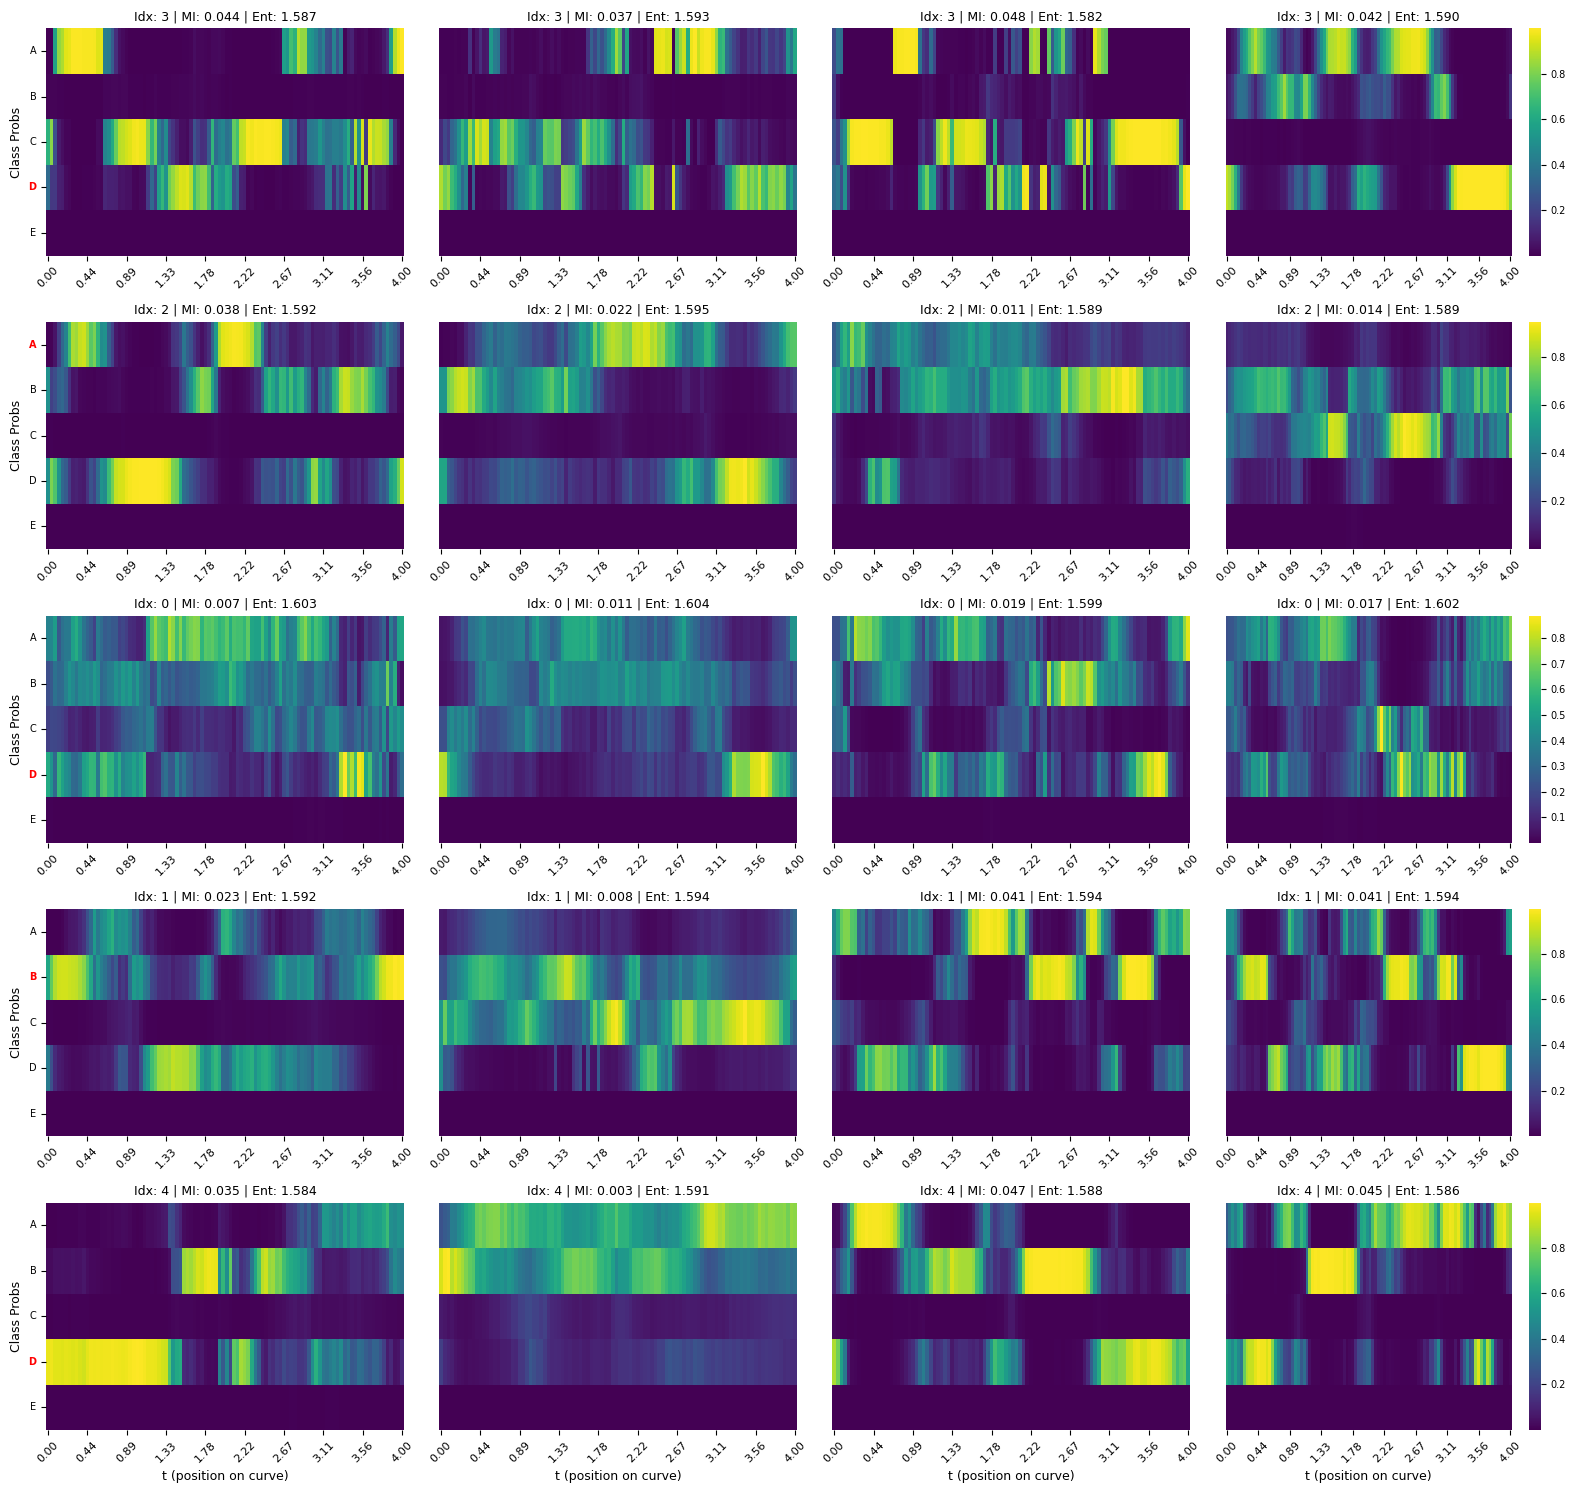

In [8]:
# Calculate Metrics and Select Top-K Uncertain Samples
# (Using the first run's probabilities for selection)

primary_probs = all_model_probs[0][0] # [num_t, num_data, num_classes]

# Calculate NLL along the curve for selection
# nll shape: [num_t, num_data]
labels = all_model_probs[0][-1]  # Assuming labels are the same across models and using the first time step for selection
nll_vals = -jnp.log(jnp.take_along_axis(primary_probs, labels[None, :, None], axis=-1).squeeze(-1))
mean_nll = nll_vals.mean(0)

TOP_K = 5
max_idx = mean_nll.argsort()[-TOP_K:][::-1]

print(f"Indices of top-{TOP_K} most uncertain samples: {max_idx}")

# Setup Heatmap Grid
num_models = len(all_model_probs)
fig, axes = plt.subplots(TOP_K, num_models, figsize=(4 * num_models, 3 * TOP_K))

# labels mapping for y-axis (ABCDE etc)
class_labels = [chr(65 + i) for i in range(primary_probs.shape[-1])]

for i, data_idx in enumerate(max_idx):
    for j in range(num_models):
        ax = axes[i, j] if TOP_K > 1 else axes[j]
        
        # probs shape: [num_t, num_classes]
        probs_sample = all_model_probs[j][0][:, data_idx, :]
        
        # Calculate MI and Entropy for this specific point/model
        mi = mutual_information(all_model_probs[j][0][:, data_idx:data_idx+1, :])
        ent = mean_entropy(all_model_probs[j][0][:, data_idx:data_idx+1, :])
        
        sns.heatmap(probs_sample.T, ax=ax, cmap='viridis', cbar=(j == num_models - 1))
        
        # Title and Formatting
        ax.set_title(f"Idx: {data_idx} | MI: {mi:.3f} | Ent: {ent:.3f}", fontsize=9)
        if i == TOP_K - 1:
            ax.set_xlabel("t (position on curve)")
        if j == 0:
            ax.set_ylabel("Class Probs")
            ax.set_yticks(np.arange(len(class_labels)) + 0.5)
            ax.set_yticklabels(class_labels, rotation=0)
            
            # Highlight correct class in red
            correct_class = int(labels[data_idx])
            for tick_label in ax.get_yticklabels():
                if int(tick_label.get_position()[1] - 0.5) == correct_class:
                    tick_label.set_color('red')
                    tick_label.set_fontweight('bold')
        else:
            ax.set_yticks([])

        num_t = probs_sample.shape[0]
        tick_indices = np.linspace(0, num_t - 1, 10)
        ax.set_xticks(tick_indices + 0.5)
        ax.set_xticklabels([f"{t:.2f}" for t in np.linspace(0, env.s_model.t_max, 10)], rotation=45, fontsize=8)

plt.tight_layout()
plt.show()


### plotting from runs

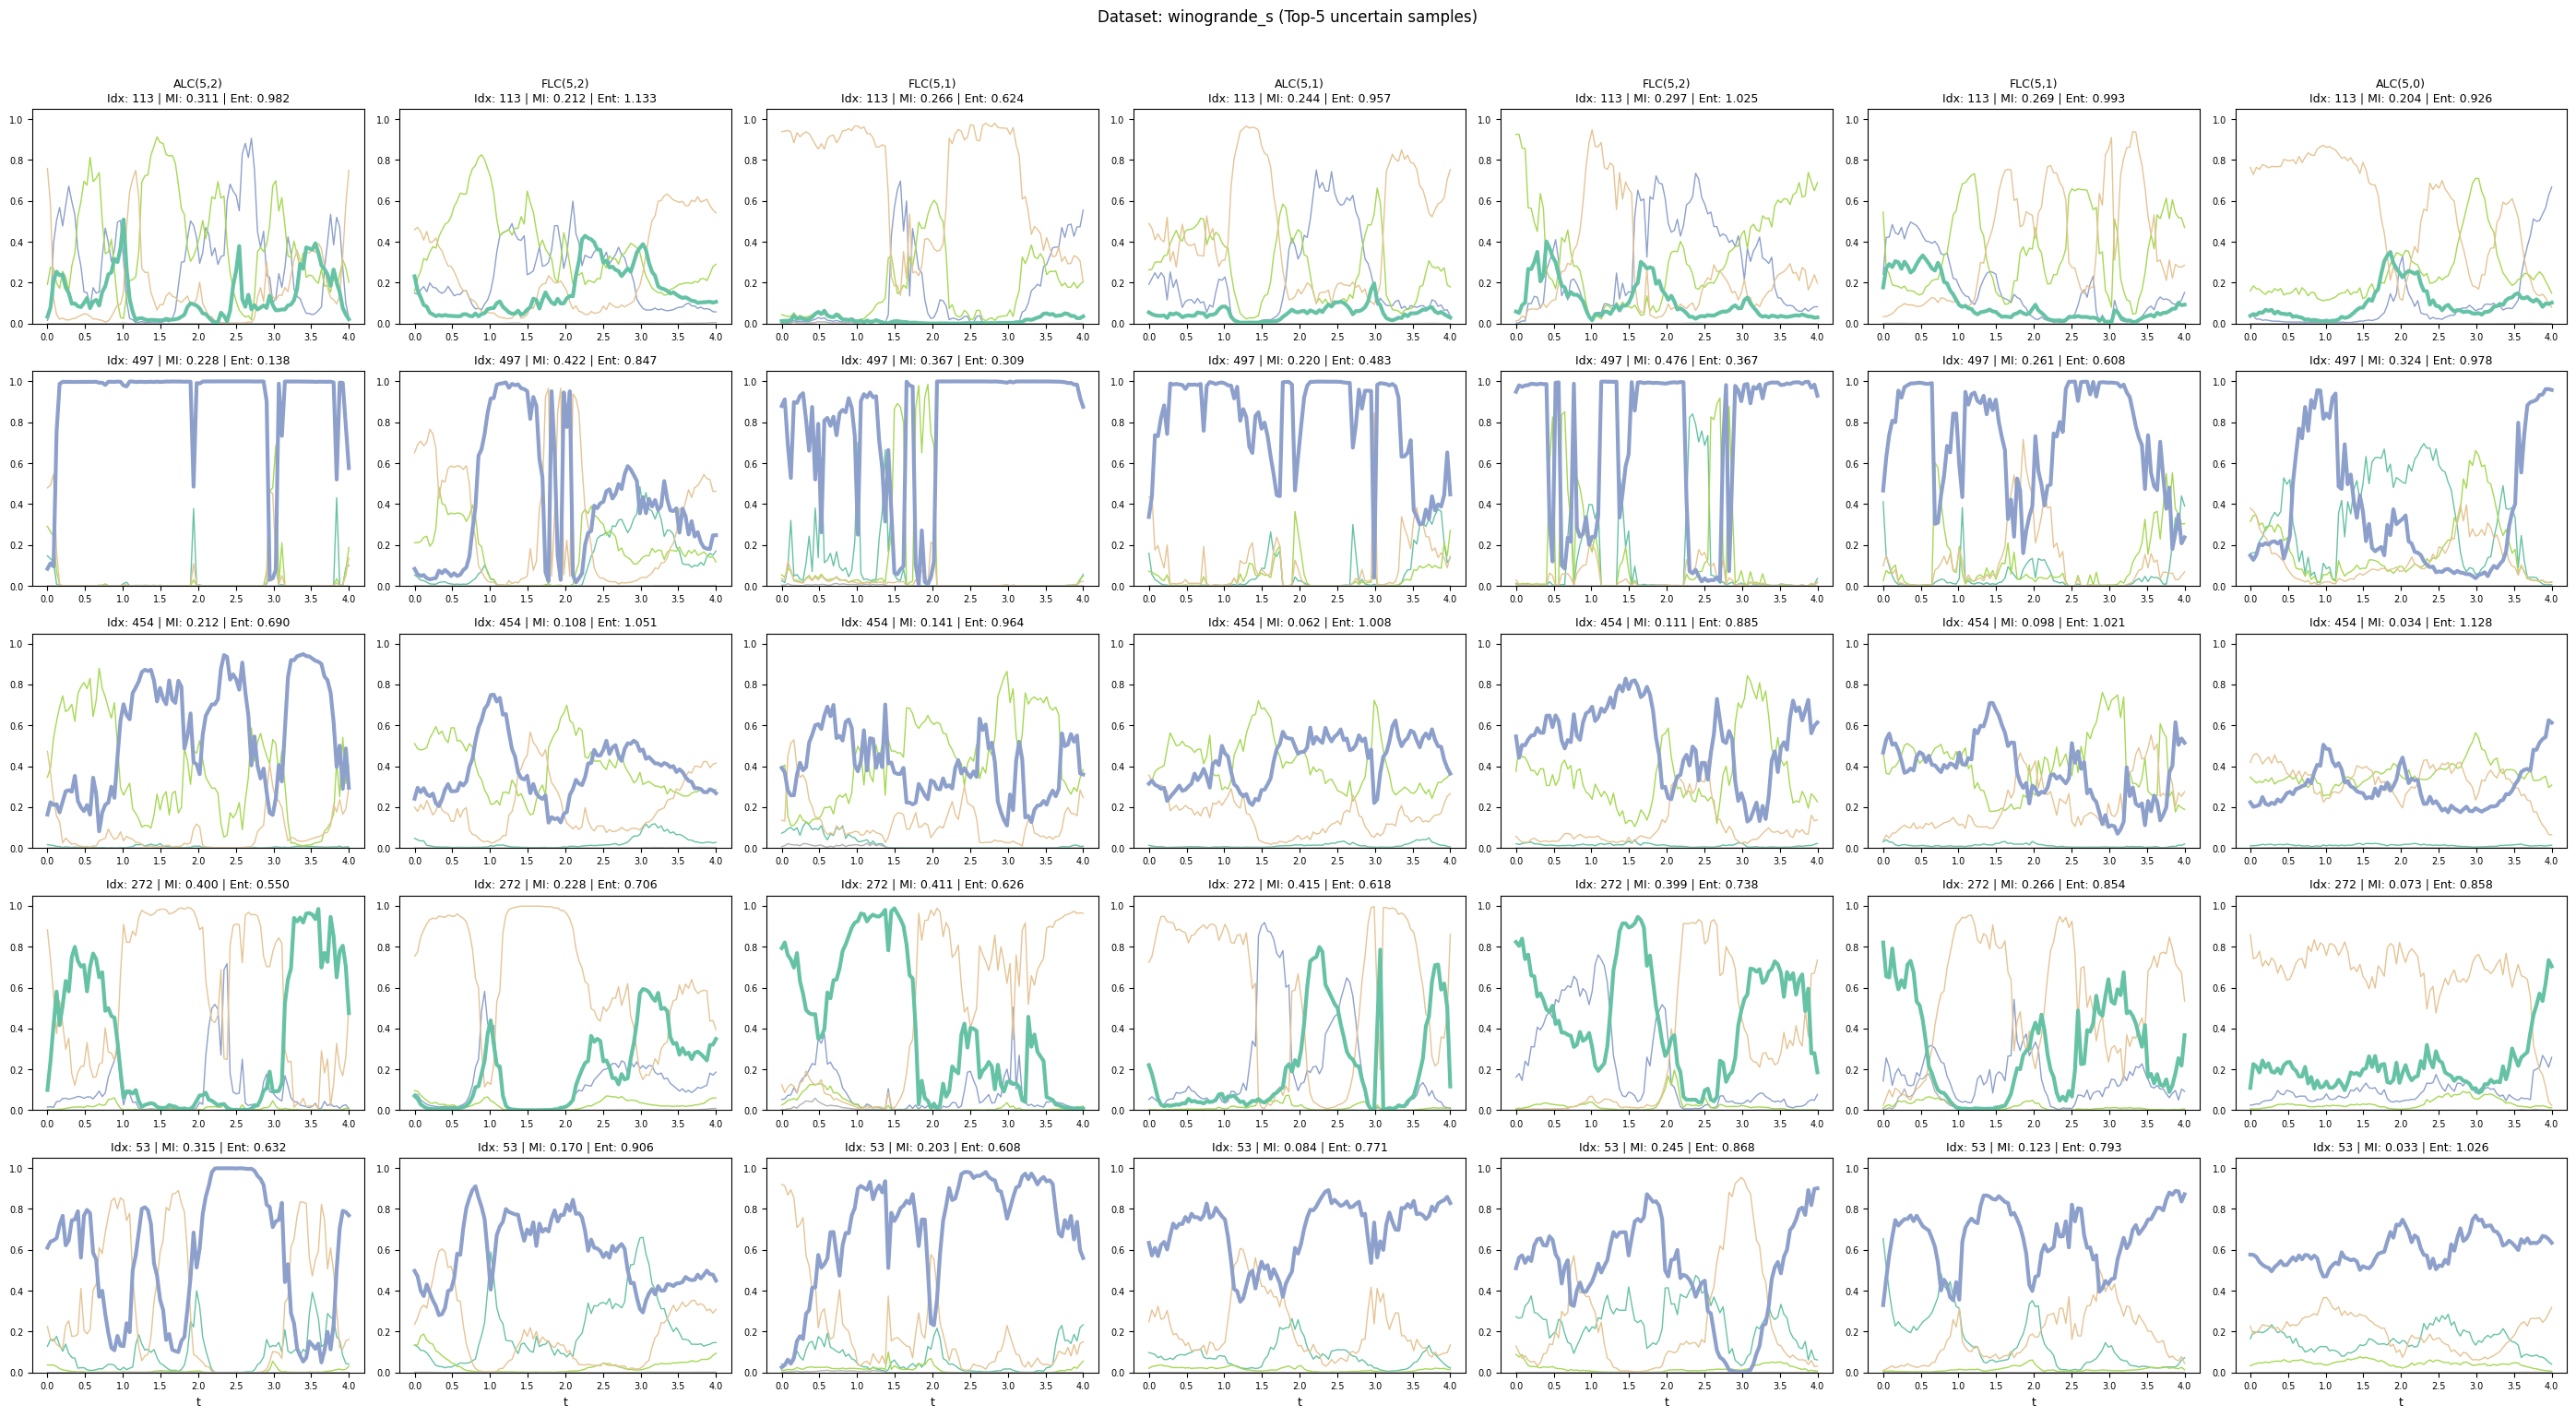

In [17]:
#!/usr/bin/env python3
import os
import argparse
import numpy as np
from scipy.special import softmax
import matplotlib.pyplot as plt
import seaborn as sns
from argparse import Namespace


def mean_entropy(probs, eps=1e-10):
    # probs: (T, K)
    ent = -np.sum(probs * np.log(probs + eps), axis=-1)
    return np.mean(ent)


def mutual_information(probs, eps=1e-10):
    # probs: (T, K)
    avg_probs = np.mean(probs, axis=0)
    bma_ent = -np.sum(avg_probs * np.log(avg_probs + eps), axis=-1)
    avg_ent = mean_entropy(probs, eps)
    return bma_ent - avg_ent

args = Namespace(
    k=5,
    # plot_type="heatmap",
    plot_type="lineplot",
    # input_dir="funct_smooth/logits_for_plotting",
    input_dir="funct_smooth/logits_backup",
    load_wandb=False,
    # dataset="winogrande_s"
    # dataset="ARC-Challenge"
    dataset="ARC-Easy"
)

files = [f for f in os.listdir(args.input_dir) if f.endswith(".npz")]
selected_files = []
for f in files:
    ds_name = f.split("_seed_")[0]
    if ds_name == args.dataset:
        selected_files.append(f)


if args.load_wandb:
    import wandb
    api = wandb.Api()

all_data = []
for f in selected_files:
    path = os.path.join(args.input_dir, f)
    d = dict(np.load(path))
    # Extract model_name from filename: {ds}_seed_{seed}_{model_name}_{run_id}.npz
    parts = f.replace(".npz", "").split("_")
    model_name = parts[-2]
    d["model_name"] = model_name

    if args.load_wandb and "wandb_path" in d:
        try:
            run_path = str(d["wandb_path"])
            print(f"Loading W&B config for {run_path}...")
            run = api.run(run_path)
            d["wandb_config"] = run.config
        except Exception as e:
            print(f"Error loading W&B run {d.get('wandb_path')}: {e}")

    all_data.append(d)

# probs: (models, T, samples, classes)
# Compute BMA entropy per sample to select top K
# BMA entropy = entropy(mean(probs over T))

sample_entropies = []
for d in all_data:
    logits = d["logits"]  # (T, samples, classes)
    probs = softmax(logits, axis=-1)
    avg_probs = np.mean(probs, axis=0)  # (samples, classes)
    ent = -np.sum(avg_probs * np.log(avg_probs + 1e-10), axis=-1)
    sample_entropies.append(ent)

# Max entropy across all models for each sample
max_ent_per_sample = np.max(np.stack(sample_entropies), axis=0)
top_k_indices = np.argsort(max_ent_per_sample)[::-1][: args.k]

num_models = len(all_data)
fig, axes = plt.subplots(
    args.k, num_models, figsize=(4 * num_models, 3 * args.k), squeeze=False
)

t_max = all_data[0]["t_max"]
n_samples = all_data[0]["n_samples"]
t_vals = np.linspace(0, t_max, n_samples)

for i, idx in enumerate(top_k_indices):
    for j, d in enumerate(all_data):
        ax = axes[i, j]
        logits_sample = d["logits"][:, idx, :]  # (T, classes)
        probs_sample = softmax(logits_sample, axis=-1)
        labels = d["labels"]
        correct_class = int(labels[idx])

        mi = mutual_information(probs_sample)
        ent = mean_entropy(probs_sample)

        title = f"Idx: {idx} | MI: {mi:.3f} | Ent: {ent:.3f}"
        if i == 0:
            title = f"{d['model_name']}\n{title}"
        ax.set_title(title, fontsize=9)

        if args.plot_type == "heatmap":
            sns.heatmap(
                probs_sample.T,
                ax=ax,
                cmap="viridis",
                cbar=(j == num_models - 1),
            )
            ax.set_yticks(np.arange(probs_sample.shape[-1]) + 0.5)
            ax.set_yticklabels(
                [chr(65 + c) for c in range(probs_sample.shape[-1])], rotation=0
            )
            for tick in ax.get_yticklabels():
                if ord(tick.get_text()) - 65 == correct_class:
                    tick.set_color("red")
                    tick.set_fontweight("bold")
        else:
            colors = plt.cm.Set2(np.linspace(0, 1, probs_sample.shape[-1]))
            for c in range(probs_sample.shape[-1]):
                if c == correct_class:
                    ax.plot(
                        t_vals, probs_sample[:, c], color=colors[c], lw=3, zorder=3
                    )
                else:
                    ax.plot(
                        t_vals, probs_sample[:, c], color=colors[c], lw=1, alpha=1.
                    )
            ax.set_ylim(0, 1.05)

        if i == args.k - 1:
            ax.set_xlabel("t")

plt.suptitle(
    f"Dataset: {ds_name} (Top-{args.k} uncertain samples)", fontsize=12, y=1.02
)
plt.tight_layout()

    # output_path = f"funct_smooth/smootheness_{ds_name}_{args.plot_type}.pdf"
    # plt.savefig(output_path, bbox_inches="tight")



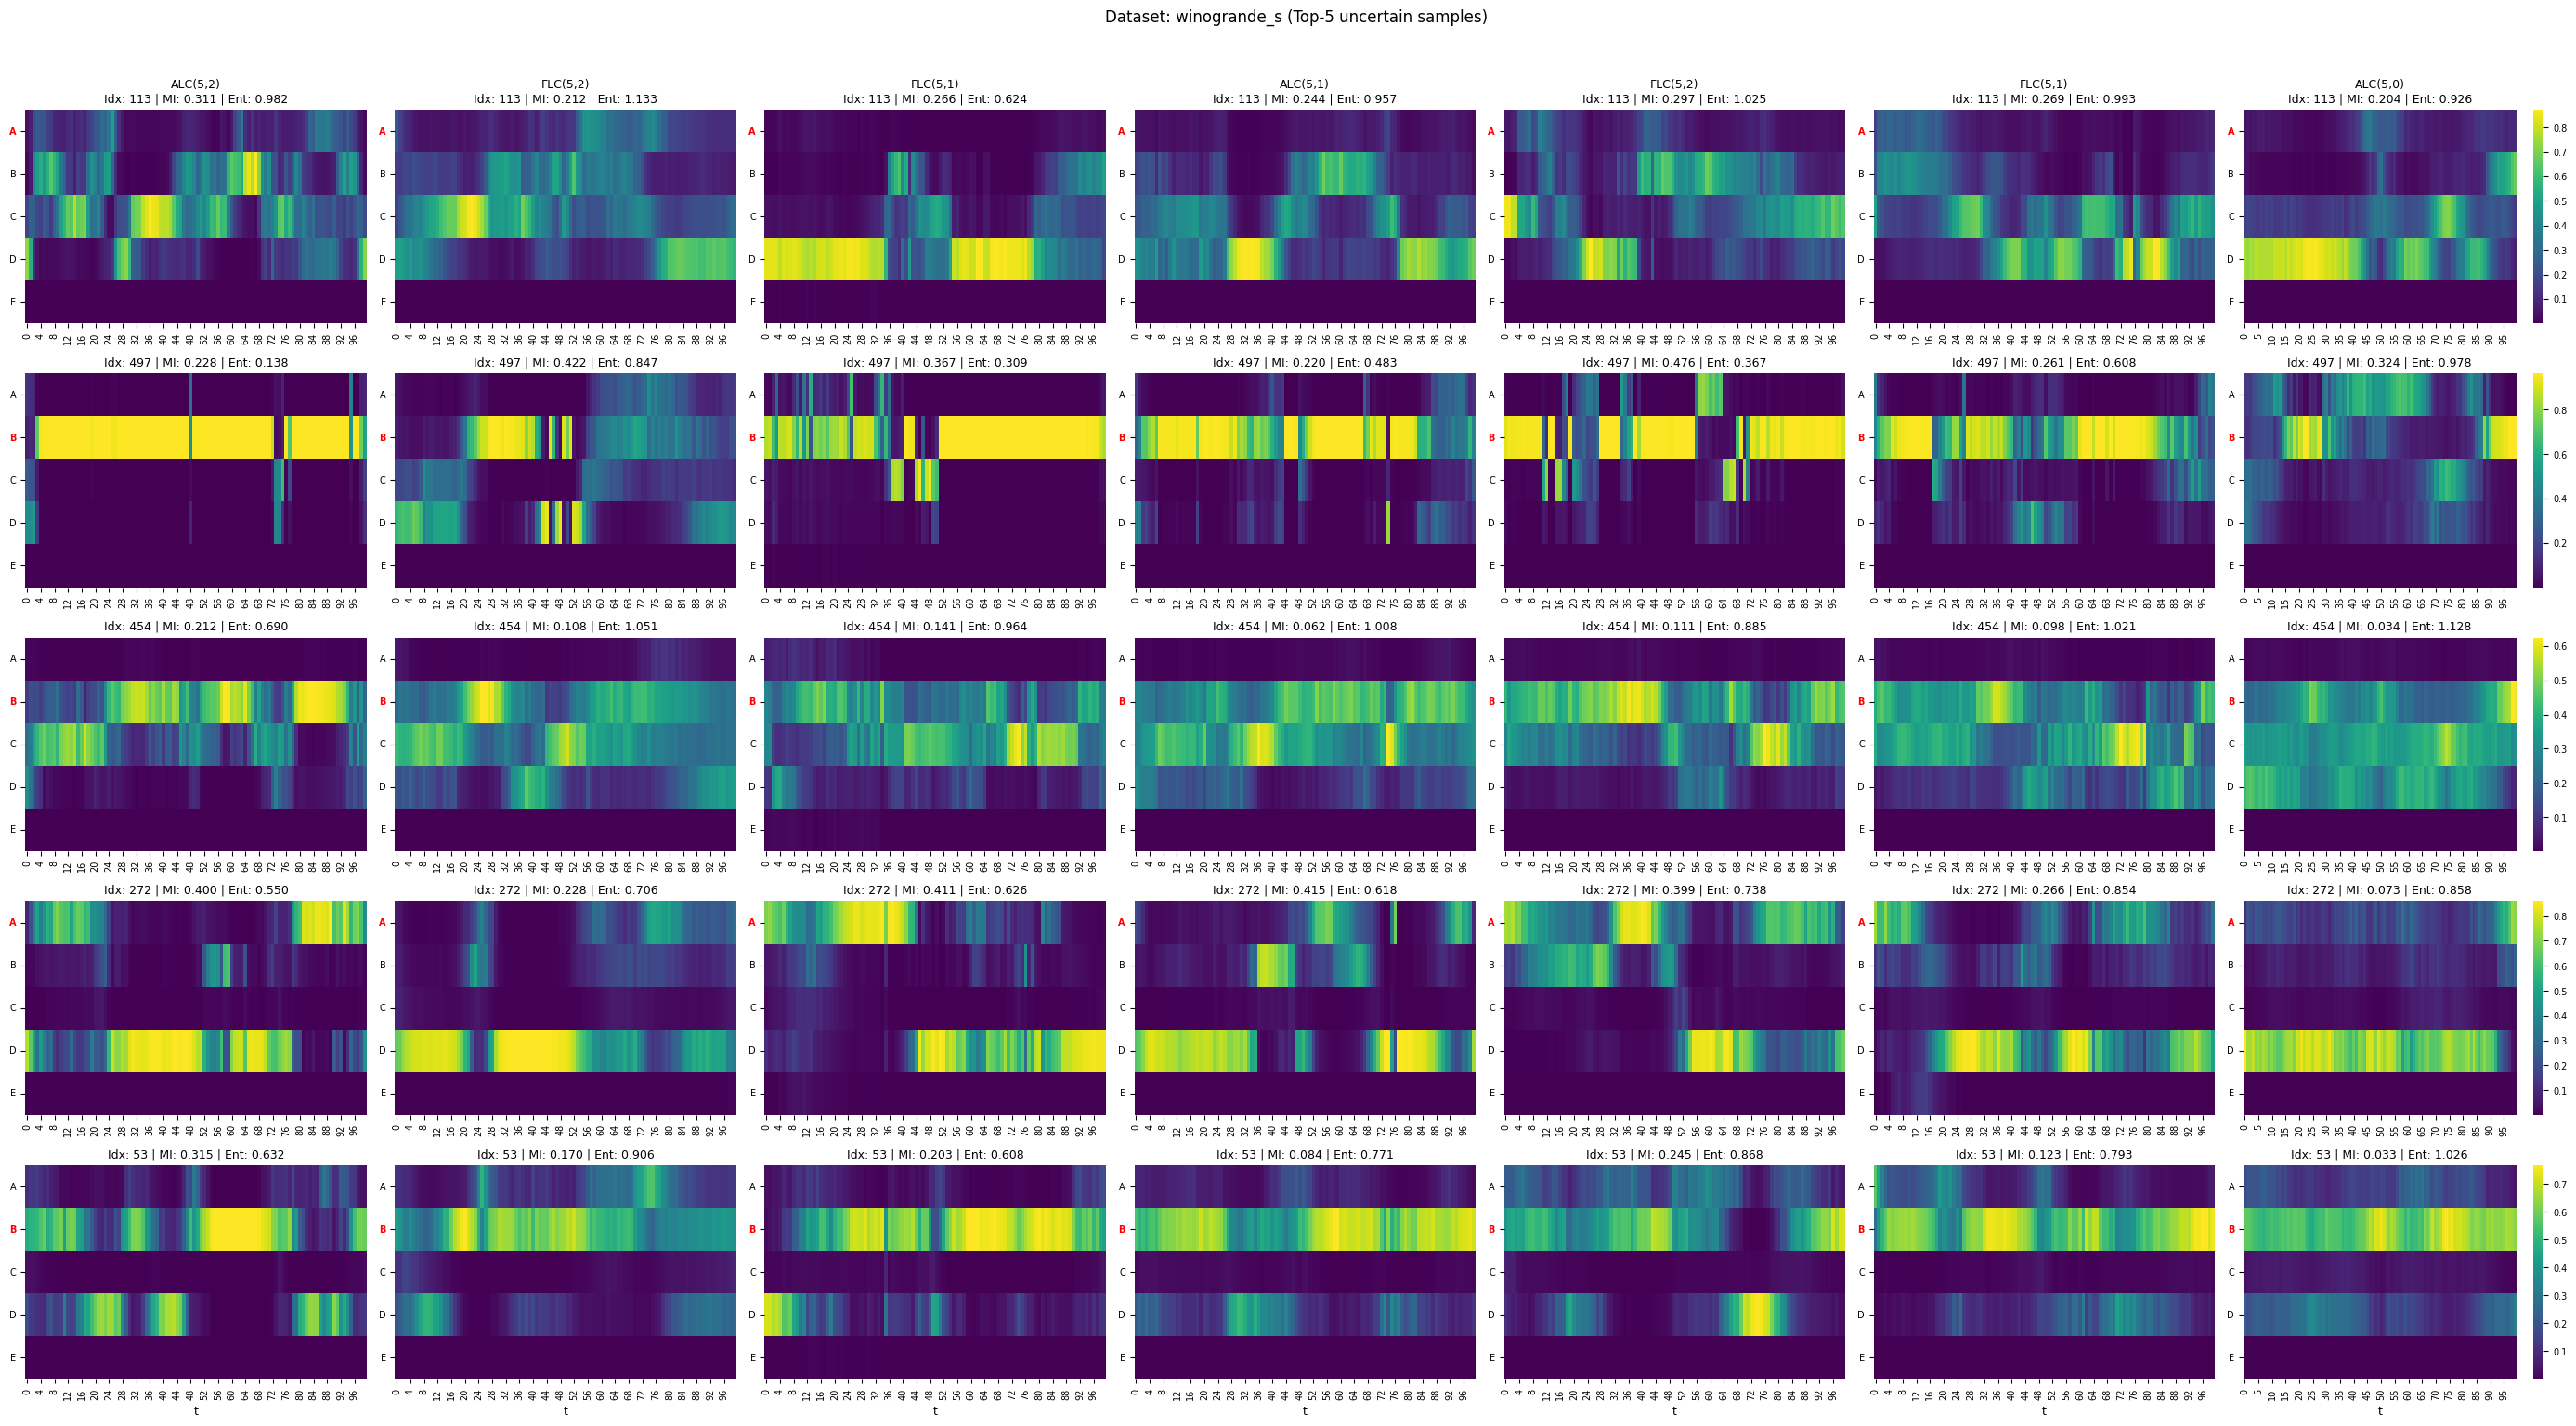

In [18]:
#!/usr/bin/env python3
import os
import argparse
import numpy as np
from scipy.special import softmax
import matplotlib.pyplot as plt
import seaborn as sns
from argparse import Namespace


def mean_entropy(probs, eps=1e-10):
    # probs: (T, K)
    ent = -np.sum(probs * np.log(probs + eps), axis=-1)
    return np.mean(ent)


def mutual_information(probs, eps=1e-10):
    # probs: (T, K)
    avg_probs = np.mean(probs, axis=0)
    bma_ent = -np.sum(avg_probs * np.log(avg_probs + eps), axis=-1)
    avg_ent = mean_entropy(probs, eps)
    return bma_ent - avg_ent

args = Namespace(
    k=5,
    plot_type="heatmap",
    # plot_type="lineplot",
    # input_dir="funct_smooth/logits_for_plotting",
    input_dir="funct_smooth/logits_backup",
    load_wandb=False,
    # dataset="winogrande_s"
    # dataset="ARC-Challenge"
    dataset="ARC-Easy"
)

files = [f for f in os.listdir(args.input_dir) if f.endswith(".npz")]
selected_files = []
for f in files:
    ds_name = f.split("_seed_")[0]
    if ds_name == args.dataset:
        selected_files.append(f)


if args.load_wandb:
    import wandb
    api = wandb.Api()

all_data = []
for f in selected_files:
    path = os.path.join(args.input_dir, f)
    d = dict(np.load(path))
    # Extract model_name from filename: {ds}_seed_{seed}_{model_name}_{run_id}.npz
    parts = f.replace(".npz", "").split("_")
    model_name = parts[-2]
    d["model_name"] = model_name

    if args.load_wandb and "wandb_path" in d:
        try:
            run_path = str(d["wandb_path"])
            print(f"Loading W&B config for {run_path}...")
            run = api.run(run_path)
            d["wandb_config"] = run.config
        except Exception as e:
            print(f"Error loading W&B run {d.get('wandb_path')}: {e}")

    all_data.append(d)

# probs: (models, T, samples, classes)
# Compute BMA entropy per sample to select top K
# BMA entropy = entropy(mean(probs over T))

sample_entropies = []
for d in all_data:
    logits = d["logits"]  # (T, samples, classes)
    probs = softmax(logits, axis=-1)
    avg_probs = np.mean(probs, axis=0)  # (samples, classes)
    ent = -np.sum(avg_probs * np.log(avg_probs + 1e-10), axis=-1)
    sample_entropies.append(ent)

# Max entropy across all models for each sample
max_ent_per_sample = np.max(np.stack(sample_entropies), axis=0)
top_k_indices = np.argsort(max_ent_per_sample)[::-1][: args.k]

num_models = len(all_data)
fig, axes = plt.subplots(
    args.k, num_models, figsize=(4 * num_models, 3 * args.k), squeeze=False
)

t_max = all_data[0]["t_max"]
n_samples = all_data[0]["n_samples"]
t_vals = np.linspace(0, t_max, n_samples)

for i, idx in enumerate(top_k_indices):
    for j, d in enumerate(all_data):
        ax = axes[i, j]
        logits_sample = d["logits"][:, idx, :]  # (T, classes)
        probs_sample = softmax(logits_sample, axis=-1)
        labels = d["labels"]
        correct_class = int(labels[idx])

        mi = mutual_information(probs_sample)
        ent = mean_entropy(probs_sample)

        title = f"Idx: {idx} | MI: {mi:.3f} | Ent: {ent:.3f}"
        if i == 0:
            title = f"{d['model_name']}\n{title}"
        ax.set_title(title, fontsize=9)

        if args.plot_type == "heatmap":
            sns.heatmap(
                probs_sample.T,
                ax=ax,
                cmap="viridis",
                cbar=(j == num_models - 1),
            )
            ax.set_yticks(np.arange(probs_sample.shape[-1]) + 0.5)
            ax.set_yticklabels(
                [chr(65 + c) for c in range(probs_sample.shape[-1])], rotation=0
            )
            for tick in ax.get_yticklabels():
                if ord(tick.get_text()) - 65 == correct_class:
                    tick.set_color("red")
                    tick.set_fontweight("bold")
        else:
            colors = plt.cm.Set2(np.linspace(0, 1, probs_sample.shape[-1]))
            for c in range(probs_sample.shape[-1]):
                if c == correct_class:
                    ax.plot(
                        t_vals, probs_sample[:, c], color=colors[c], lw=3, zorder=3
                    )
                else:
                    ax.plot(
                        t_vals, probs_sample[:, c], color=colors[c], lw=1, alpha=1.
                    )
            ax.set_ylim(0, 1.05)

        if i == args.k - 1:
            ax.set_xlabel("t")

plt.suptitle(
    f"Dataset: {ds_name} (Top-{args.k} uncertain samples)", fontsize=12, y=1.02
)
plt.tight_layout()

    # output_path = f"funct_smooth/smootheness_{ds_name}_{args.plot_type}.pdf"
    # plt.savefig(output_path, bbox_inches="tight")



In [11]:
from jax import numpy as jnp

data = []
data_ood = []
for f in ["ARC-Challenge_seed_1_ALC(2,1)_soclgf67.npz", ]:
    data.append(jnp.load(f"funct_smooth/logits_backup/{f}", allow_pickle=True))
    data_ood.append(jnp.load(f"funct_smooth/logits_backup/{f.replace('.npz', '_ood.npz')}", allow_pickle=True))
data[0]['labels']

array([3, 2, 3, 0, 1, 2, 2, 2, 2, 3, 3, 3, 0, 1, 0, 2, 3, 1, 3, 0, 1, 1,
       3, 1, 0, 0, 3, 1, 3, 0, 1, 1, 3, 3, 3, 0, 0, 1, 3, 3, 2, 3, 3, 1,
       2, 1, 2, 3, 1, 0, 2, 2, 3, 0, 3, 3, 1, 1, 3, 0, 3, 0, 1, 3, 3, 1,
       2, 2, 1, 0, 2, 1, 3, 2, 1, 1, 0, 3, 3, 2, 0, 3, 3, 0, 0, 0, 1, 2,
       0, 1, 2, 3, 3, 1, 0, 1, 2, 0, 1, 0, 2, 2, 1, 2, 0, 2, 2, 2, 1, 3,
       2, 0, 3, 3, 1, 0, 3, 1, 1, 3, 3, 1, 3, 3, 3, 0, 3, 0, 2, 0, 1, 2,
       3, 0, 2, 3, 2, 0, 1, 2, 0, 3, 0, 3, 1, 2, 0, 1, 1, 1, 3, 3, 0, 0,
       2, 2, 0, 2, 1, 3, 0, 0, 1, 2, 2, 2, 1, 0, 3, 1, 3, 3, 1, 1, 2, 1,
       2, 0, 0, 3, 2, 1, 0, 1, 3, 2, 1, 3, 0, 2, 1, 2, 3, 2, 2, 2, 2, 0,
       2, 0, 2, 2, 1, 1, 3, 3, 2, 1, 2, 1, 4, 1, 1, 0, 2, 0, 2, 1, 0, 3,
       3, 2, 3, 3, 0, 1, 2, 3, 0, 1, 1, 1, 0, 3, 3, 2, 2, 1, 3, 2, 0, 1,
       3, 0, 3, 0, 0, 1, 3, 1, 2, 3, 0, 0, 3, 2, 3, 3, 2, 0, 0, 1, 2, 2,
       0, 0, 2, 1, 3, 3, 0, 1, 1, 1, 3, 0, 2, 2, 2, 1, 3, 3, 2, 1, 2, 2,
       2, 2, 1, 2, 3, 2, 3, 3, 2, 1, 2, 3, 3], dtyp

### make plot from preruns

In [5]:
def get_figsize(columnwidth, wf=0.5, hf=(5.**0.5-1.0)/2.0, ):
    """Parameters:
    - wf [float]:  width fraction in columnwidth units
    - hf [float]:  height fraction in columnwidth units.
                    Set by default to golden ratio.
    - columnwidth [float]: width of the column in latex. Get this from LaTeX 
                            using \showthe\columnwidth
    Returns:  [fig_width,fig_height]: that should be given to matplotlib
    """
    fig_width_pt = columnwidth*wf
    inches_per_pt = 1.0/72.27               # Convert pt to inch
    fig_width = fig_width_pt*inches_per_pt  # width in inches
    fig_height = fig_width*hf      # height in inches
    return [fig_width, fig_height]


# fig_width_pt = 234.8  # Get this from LaTeX using \showthe\columnwidth
fig_width_pt = 397.48499  # Get this from LaTeX using \showthe\columnwidth
inches_per_pt = 1.0/72.27               # Convert pt to inches
golden_mean = (np.sqrt(5)-1.0)/2.0         # Aesthetic ratio
fig_width = fig_width_pt*inches_per_pt  # width in inches
fig_height = fig_width*golden_mean       # height in inches
figsize = [fig_width, fig_height]
print("Figure size=", figsize)
tex_fonts = {
    # Use LaTeX to write all text
    "text.usetex": True,
    # "text.latex.preamble": r"\usepackage{amsmath}",  # This provides \text{}
    # "text.latex.preamble": r'\usepackage{amsfonts}',
    "font.family": "Nimbus Sans",
    # Use 10pt font in plots, to match 10pt font in document
    "axes.labelsize": 10,
    "font.size": 10,
    # Make the legend/label fonts a little smaller
    "legend.fontsize": 9,
    "legend.title_fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.figsize": figsize
}
plt.rcParams.update(tex_fonts)

Figure size= [5.499999861629998, 3.399186852607058]


Loading models and W&B configs...

Generating plots...


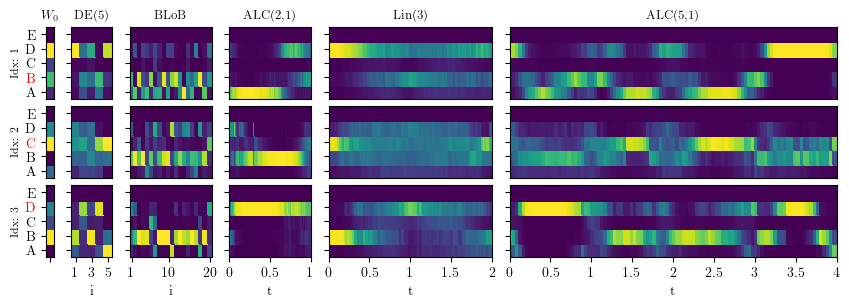

In [6]:
import os
import numpy as np
from scipy.special import softmax
import matplotlib.pyplot as plt
import wandb

# ==========================================
# 1. CONFIGURATION
# ==============a============================
INPUT_DIR = "funct_smooth/logits_backup"
DATASET_NAME = "ARC-Challenge"
PLOT_TYPE = "heatmap"

# Explicit files to plot (in order)
FILES = [
    "ARC-Challenge_QWEN.npz",
    "ARC-Challenge_seed_1_DE(5,1)_tic8pnpz.npz",
    "ARC-Challenge_seed_2_BLOB_logits.npz",
    "ARC-Challenge_seed_1_ALC(2,1)_soclgf67.npz",
    "ARC-Challenge_seed_1_ALC(3,0)_8a0ijuua.npz",
    "ARC-Challenge_seed_1_ALC(5,1)_tic8pnpz.npz"
]

# Explicit sample indices
MAIN_INDICES = [149, 174, 72]
# OOD_INDICES = [2, 5, 6]
OOD_INDICES = []

# ==========================================
# 2. HELPER FUNCTIONS
# ==========================================
def mean_entropy(probs, eps=1e-10):
    return np.mean(-np.sum(probs * np.log(probs + eps), axis=-1))

def mutual_information(probs, eps=1e-10):
    avg_probs = np.mean(probs, axis=0)
    bma_ent = -np.sum(avg_probs * np.log(avg_probs + eps), axis=-1)
    return bma_ent - mean_entropy(probs, eps)

# ==========================================
# 3. DATA LOADING
# ==========================================
if not os.path.exists(INPUT_DIR):
    raise FileNotFoundError(f"Directory {INPUT_DIR} does not exist.")

api = wandb.Api()
all_data = []
ood_rows = []
all_files_in_dir = set(os.listdir(INPUT_DIR))

print("Loading models and W&B configs...")
for f in FILES:
    path = os.path.join(INPUT_DIR, f)
    if not os.path.exists(path):
        print(f"⚠️ Warning: {path} not found. Skipping.")
        continue
        
    d = dict(np.load(path, allow_pickle=True))
    d["filename"] = f

    # Metadata extraction
    if "_QWEN.npz" in f:
        run_id = "BASE"
        model_name = "QWEN"
    else:
        parts = f.replace(".npz", "").split("_")
        run_id = parts[-1]
        model_name = parts[-2]

    d["run_id"] = run_id
    d["t_max"] = d.get("t_max", 1.0) # Default to 1.0 if missing

    # W&B Config Loading
    if "wandb_path" in d:
        try:
            wp = d["wandb_path"]
            run_path = "/".join(wp.tolist()) if isinstance(wp, np.ndarray) and wp.size == 3 else str(np.array(wp).flatten()[0])
            run = api.run(run_path)
            sub_model = run.config.get("model_params", {}).get("subspace_model", "unknown")
            # d["model_name"] = f"{model_name} ({run_id})\n({sub_model})"
            d["model_name"] = f"{model_name}"
        except Exception:
            d["model_name"] = f"{model_name} ({run_id})"
    else:
        d["model_name"] = f"{model_name}"

    all_data.append(d)

    # Load corresponding OOD data
    expected_ood = f.replace(".npz", "_ood.npz")
    if expected_ood in all_files_in_dir:
        ood_data = dict(np.load(os.path.join(INPUT_DIR, expected_ood), allow_pickle=True))
        ood_rows.append(ood_data)
    else:
        ood_rows.append(None)

# ==========================================
# 4. PLOTTING LOGIC
# ==========================================
if not all_data:
    raise ValueError("No valid data loaded. Check your file paths.")

total_rows = len(MAIN_INDICES) + len(OOD_INDICES)
num_models = len(all_data)

# Calculate grid widths dynamically
width_ratios = []
for d in all_data:
    if d["run_id"] == "BASE":
        width_ratios.append(0.1)
    elif "DE(" in d["filename"]:
        width_ratios.append(0.1 * d["logits"].shape[0])
    else:
        width_ratios.append(d["t_max"])

fig = plt.figure(figsize=(1. * sum(width_ratios), 1. * total_rows))
gs = fig.add_gridspec(total_rows, num_models, width_ratios=width_ratios)
axes = np.array([[fig.add_subplot(gs[i, j]) for j in range(num_models)] for i in range(total_rows)])

print("\nGenerating plots...")
for i in range(total_rows):
    is_ood = i >= len(MAIN_INDICES)
    sample_idx = OOD_INDICES[i - len(MAIN_INDICES)] if is_ood else MAIN_INDICES[i]

    for j, d in enumerate(all_data):
        ax = axes[i, j]
        current_data = ood_rows[j] if is_ood else d
        
        # Skip empty OOD bounds
        if current_data is None or sample_idx >= current_data["logits"].shape[1]:
            ax.axis("off")
            continue

        logits_sample = current_data["logits"][:, sample_idx, :]  
        probs_sample = softmax(logits_sample, axis=-1)
        
        # Parse labels securely
        label_val = current_data["labels"][sample_idx]
        if isinstance(label_val, (list, np.ndarray)):
            correct_classes = [int(c) for c in label_val]
        elif label_val is None or (isinstance(label_val, (int, np.integer)) and label_val < 0):
            correct_classes = []
        else:
            correct_classes = [int(label_val)]

        # Formatting metrics
        mi = mutual_information(probs_sample)
        ent = mean_entropy(probs_sample)
        row_type = "OOD" if is_ood else "Idx"
        title = f"{row_type}: {sample_idx} | MI: {mi:.3f} | Ent: {ent:.3f}"
        if i == 0:
            title = f"{d['model_name']}"
            if "QWEN" in title:
                title = r"$W_0$"
            elif "ALC(3,0)" in title:
                title = "Lin(3)"
            elif "DE(5,1)" in title:
                title = "DE(5)"
            elif "BLOB" in title:
                title = "BLoB"
            ax.set_title(title, fontsize=9)
            # title = f"{d['model_name']}\n{title}"
        # ax.set_title(title, fontsize=9)
        # row_label = f"{row_type}: {sample_idx}"
        row_label = f"{row_type}: {i+1}"
        if j == 0:
            ax.set_ylabel(row_label, fontsize=8)
        else:
            ax.set_yticks([])

        # Plot generation
        if PLOT_TYPE == "heatmap":
            X = np.linspace(0, current_data.get("t_max", 1.0), probs_sample.shape[0] + 1)
            Y = np.arange(probs_sample.shape[1] + 1)
            mesh = ax.pcolormesh(X, Y, probs_sample.T, cmap="viridis", edgecolors="face", shading="auto")

            # if (j == num_models - 1) and (i==2):
            #     plt.colorbar(mesh, ax=ax)

            ax.set_yticks(np.arange(probs_sample.shape[-1]) + 0.5)
            # Only show Y-labels on the first column to save space
            if j > 0: 
                ax.set_yticklabels([])
            else:
                ax.set_yticklabels([chr(65 + c) for c in range(probs_sample.shape[-1])], rotation=0)
                for tick in ax.get_yticklabels():
                    if (ord(tick.get_text()) - 65) in correct_classes:
                        tick.set_color("red")
                        tick.set_fontweight("bold")

            ax.set_xticks([]) 
            
            # --- CUSTOM X-TICKS FOR BOTTOM ROW ---
            if i == total_rows - 1:
                if "BLOB" in d["filename"] or "DE(" in d["filename"]:
                    # Calculate center position of each box for discrete models
                    centers = (X[:-1] + X[1:]) / 2
                    if "BLOB" in d["filename"]:
                        # You explicitly want labels 1, 10, and the last one (20)
                        # These correspond to array indices 0, 9, and -1
                        target_indices = [0, 9, -1]
                        ax.set_xticks(centers[target_indices])
                        # Dynamically use len(centers) so if it's 20, it prints "20"
                        ax.set_xticklabels(["1", "10", str(len(centers))]) 
                        ax.set_xlabel("i")
                        
                    else: 
                        # DE model logic: usually 5 models, step of 2 gives 1, 3, 5
                        step = 2
                        ax.set_xticks(centers[::step])
                        ax.set_xticklabels([str(idx + 1) for idx in range(len(centers))][::step])
                        ax.set_xlabel("i")
                elif d["run_id"] == "BASE":
                    # For the base model, we can use the actual t values if available
                    ax.set_xticks([0.5])
                    ax.set_xticklabels([""])
                    ax.set_xlabel("")
                else:
                    # Standard time axis for continuous models
                    tick_vals = np.arange(0, current_data.get("t_max", 1.0) + 1e-5, 0.5)
                    ax.set_xticks(tick_vals)
                    ax.set_xticklabels([f"{val:.1f}" if val != int(val) else f"{int(val)}" for val in tick_vals])
                    ax.set_xlabel("t")
                    
                ax.set_xlim(0, current_data.get("t_max", 1.0))

# plt.suptitle(f"Dataset: {DATASET_NAME} | Main rows: {len(MAIN_INDICES)} | OOD rows: {len(OOD_INDICES)}", fontsize=12, y=1.02)
plt.tight_layout()
plt.subplots_adjust(top=0.95, hspace=0.1, wspace=0.15)

# Show inline in Jupyter
plt.savefig(f"funct_smooth/smootheness_{DATASET_NAME}_{PLOT_TYPE}_final.pdf", bbox_inches="tight")

Loading models and W&B configs...

Generating plots for 8 rows...


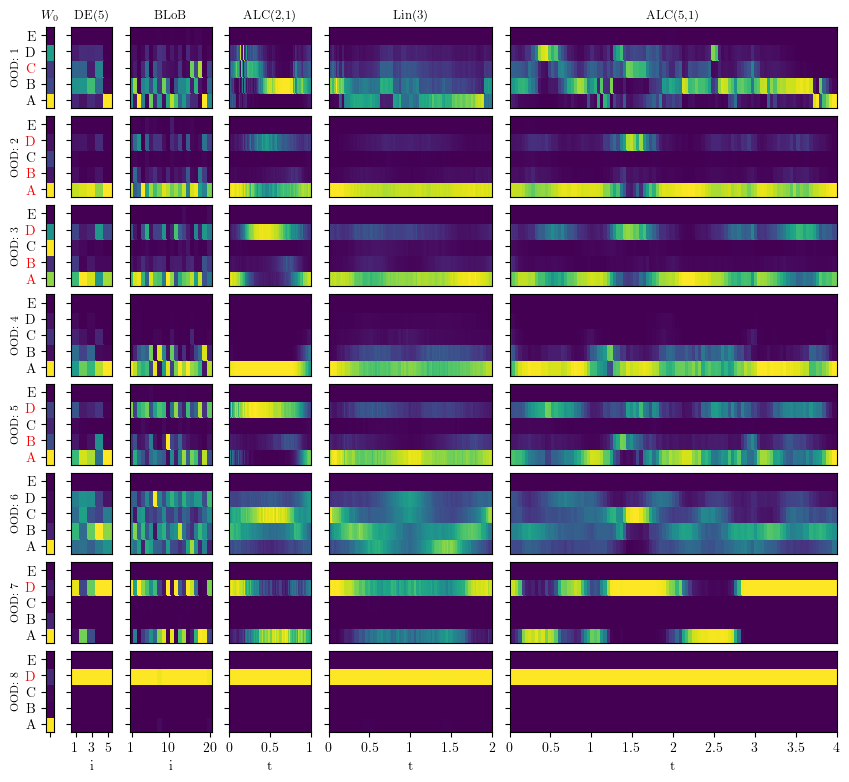

In [7]:
import os
import numpy as np
from scipy.special import softmax
import matplotlib.pyplot as plt
import wandb

# ==========================================
# 1. CONFIGURATION
# ==============a============================
INPUT_DIR = "funct_smooth/logits_backup"
DATASET_NAME = "ARC-Challenge"
PLOT_TYPE = "heatmap"

# Explicit files to plot (in order)
FILES = [
    "ARC-Challenge_QWEN.npz",
    "ARC-Challenge_seed_1_DE(5,1)_tic8pnpz.npz",
    "ARC-Challenge_seed_2_BLOB_logits.npz",
    "ARC-Challenge_seed_1_ALC(2,1)_soclgf67.npz",
    "ARC-Challenge_seed_1_ALC(3,0)_8a0ijuua.npz",
    "ARC-Challenge_seed_1_ALC(5,1)_tic8pnpz.npz"
]

# Explicit sample indices
# MAIN_INDICES = [149, 174, 72]
MAIN_INDICES = []
# OOD_INDICES = [2, 5, 6]
OOD_INDICES = [0,1,2,3,4,5,6,7]

# ==========================================
# 2. HELPER FUNCTIONS
# ==========================================
def mean_entropy(probs, eps=1e-10):
    return np.mean(-np.sum(probs * np.log(probs + eps), axis=-1))

def mutual_information(probs, eps=1e-10):
    avg_probs = np.mean(probs, axis=0)
    bma_ent = -np.sum(avg_probs * np.log(avg_probs + eps), axis=-1)
    return bma_ent - mean_entropy(probs, eps)

# ==========================================
# 3. DATA LOADING
# ==========================================
if not os.path.exists(INPUT_DIR):
    raise FileNotFoundError(f"Directory {INPUT_DIR} does not exist.")

api = wandb.Api()
all_data = []
ood_rows = []
all_files_in_dir = set(os.listdir(INPUT_DIR))

print("Loading models and W&B configs...")
for f in FILES:
    path = os.path.join(INPUT_DIR, f)
    if not os.path.exists(path):
        print(f"⚠️ Warning: {path} not found. Skipping.")
        continue
        
    d = dict(np.load(path, allow_pickle=True))
    d["filename"] = f

    # Metadata extraction
    if "_QWEN.npz" in f:
        run_id = "BASE"
        model_name = "QWEN"
    else:
        parts = f.replace(".npz", "").split("_")
        run_id = parts[-1]
        model_name = parts[-2]

    d["run_id"] = run_id
    d["t_max"] = d.get("t_max", 1.0) # Default to 1.0 if missing

    # W&B Config Loading
    if "wandb_path" in d:
        try:
            wp = d["wandb_path"]
            run_path = "/".join(wp.tolist()) if isinstance(wp, np.ndarray) and wp.size == 3 else str(np.array(wp).flatten()[0])
            run = api.run(run_path)
            sub_model = run.config.get("model_params", {}).get("subspace_model", "unknown")
            # d["model_name"] = f"{model_name} ({run_id})\n({sub_model})"
            d["model_name"] = f"{model_name}"
        except Exception:
            d["model_name"] = f"{model_name} ({run_id})"
    else:
        d["model_name"] = f"{model_name}"

    all_data.append(d)

    # Load corresponding OOD data
    expected_ood = f.replace(".npz", "_ood.npz")
    if expected_ood in all_files_in_dir:
        ood_data = dict(np.load(os.path.join(INPUT_DIR, expected_ood), allow_pickle=True))
        ood_rows.append(ood_data)
    else:
        ood_rows.append(None)

# ==========================================
# 4. PLOTTING LOGIC
# ==========================================
if not all_data:
    raise ValueError("No valid data loaded. Check your file paths.")

total_rows = len(MAIN_INDICES) + len(OOD_INDICES)
num_models = len(all_data)

# Calculate grid widths dynamically
width_ratios = []
for d in all_data:
    if d["run_id"] == "BASE":
        width_ratios.append(0.1)
    elif "DE(" in d["filename"]:
        width_ratios.append(0.1 * d["logits"].shape[0])
    else:
        width_ratios.append(d["t_max"])

fig = plt.figure(figsize=(1. * sum(width_ratios), 1. * total_rows))
gs = fig.add_gridspec(total_rows, num_models, width_ratios=width_ratios)
axes = np.array([[fig.add_subplot(gs[i, j]) for j in range(num_models)] for i in range(total_rows)])

print(f"\nGenerating plots for {total_rows} rows...")
for i in range(total_rows):
    is_ood = i >= len(MAIN_INDICES)
    sample_idx = OOD_INDICES[i - len(MAIN_INDICES)] if is_ood else MAIN_INDICES[i]

    for j, d in enumerate(all_data):
        ax = axes[i, j]
        current_data = ood_rows[j] if is_ood else d
        
        # Skip empty OOD bounds
        if current_data is None or sample_idx >= current_data["logits"].shape[1]:
            ax.axis("off")
            continue

        logits_sample = current_data["logits"][:, sample_idx, :]  
        probs_sample = softmax(logits_sample, axis=-1)
        
        # Parse labels securely
        label_val = current_data["labels"][sample_idx]
        if isinstance(label_val, (list, np.ndarray)):
            correct_classes = [int(c) for c in label_val]
        elif label_val is None or (isinstance(label_val, (int, np.integer)) and label_val < 0):
            correct_classes = []
        else:
            correct_classes = [int(label_val)]

        # Formatting metrics
        mi = mutual_information(probs_sample)
        ent = mean_entropy(probs_sample)
        row_type = "OOD" if is_ood else "Idx"
        title = f"{row_type}: {sample_idx} | MI: {mi:.3f} | Ent: {ent:.3f}"
        if i == 0:
            title = f"{d['model_name']}"
            if "QWEN" in title:
                title = r"$W_0$"
            elif "ALC(3,0)" in title:
                title = "Lin(3)"
            elif "BLOB" in title:
                title = "BLoB"
            elif "DE(5,1)" in title:
                title = "DE(5)"
            ax.set_title(title, fontsize=9)
            # title = f"{d['model_name']}\n{title}"
        # ax.set_title(title, fontsize=9)
        # row_label = f"{row_type}: {sample_idx}"
        row_label = f"{row_type}: {i+1}"
        if j == 0:
            ax.set_ylabel(row_label, fontsize=8)
        else:
            ax.set_yticks([])

        # Plot generation
        if PLOT_TYPE == "heatmap":
            X = np.linspace(0, current_data.get("t_max", 1.0), probs_sample.shape[0] + 1)
            Y = np.arange(probs_sample.shape[1] + 1)
            mesh = ax.pcolormesh(X, Y, probs_sample.T, cmap="viridis", edgecolors="face", shading="auto")

            # if (j == num_models - 1) and (i==2):
            #     plt.colorbar(mesh, ax=ax)

            ax.set_yticks(np.arange(probs_sample.shape[-1]) + 0.5)
            # Only show Y-labels on the first column to save space
            if j > 0: 
                ax.set_yticklabels([])
            else:
                ax.set_yticklabels([chr(65 + c) for c in range(probs_sample.shape[-1])], rotation=0)
                for tick in ax.get_yticklabels():
                    if (ord(tick.get_text()) - 65) in correct_classes:
                        tick.set_color("red")
                        tick.set_fontweight("bold")

            ax.set_xticks([]) 
            
            # --- CUSTOM X-TICKS FOR BOTTOM ROW ---
            if i == total_rows - 1:
                if "BLOB" in d["filename"] or "DE(" in d["filename"]:
                    # Calculate center position of each box for discrete models
                    centers = (X[:-1] + X[1:]) / 2
                    if "BLOB" in d["filename"]:
                        # You explicitly want labels 1, 10, and the last one (20)
                        # These correspond to array indices 0, 9, and -1
                        target_indices = [0, 9, -1]
                        ax.set_xticks(centers[target_indices])
                        # Dynamically use len(centers) so if it's 20, it prints "20"
                        ax.set_xticklabels(["1", "10", str(len(centers))]) 
                        ax.set_xlabel("i")
                        
                    else: 
                        # DE model logic: usually 5 models, step of 2 gives 1, 3, 5
                        step = 2
                        ax.set_xticks(centers[::step])
                        ax.set_xticklabels([str(idx + 1) for idx in range(len(centers))][::step])
                        ax.set_xlabel("i")
                elif d["run_id"] == "BASE":
                    # For the base model, we can use the actual t values if available
                    ax.set_xticks([0.5])
                    ax.set_xticklabels([""])
                    ax.set_xlabel("")
                else:
                    # Standard time axis for continuous models
                    tick_vals = np.arange(0, current_data.get("t_max", 1.0) + 1e-5, 0.5)
                    ax.set_xticks(tick_vals)
                    ax.set_xticklabels([f"{val:.1f}" if val != int(val) else f"{int(val)}" for val in tick_vals])
                    ax.set_xlabel("t")
                    
                ax.set_xlim(0, current_data.get("t_max", 1.0))

# plt.suptitle(f"Dataset: {DATASET_NAME} | Main rows: {len(MAIN_INDICES)} | OOD rows: {len(OOD_INDICES)}", fontsize=12, y=1.02)
plt.tight_layout()
plt.subplots_adjust(top=0.95, hspace=0.1, wspace=0.15)

# Show inline in Jupyter
plt.savefig(f"funct_smooth/smootheness_{DATASET_NAME}_{PLOT_TYPE}_final_OOD.pdf", bbox_inches="tight")

In [120]:
len(MAIN_INDICES), len(OOD_INDICES)

(0, 10)

Loading models and W&B configs...

Generating plots...


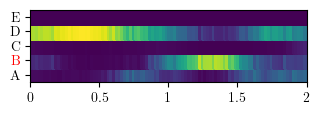

In [20]:
import os
import numpy as np
from scipy.special import softmax
import matplotlib.pyplot as plt
import wandb

# ==========================================
# 1. CONFIGURATION
# ==============a============================
INPUT_DIR = "funct_smooth/logits_backup"
DATASET_NAME = "ARC-Challenge"
PLOT_TYPE = "heatmap"

# Explicit files to plot (in order)
FILES = [
    "ARC-Challenge_seed_1_ALC(3,1)_r7trynb3.npz",
    # "ARC-Challenge_seed_1_FLC(3,1)_4pshyv56.npz",
]

# Explicit sample indices
MAIN_INDICES = [149, 174, 72]
MAIN_INDICES = [149,]
# OOD_INDICES = [2, 5, 6]
OOD_INDICES = []

# ==========================================
# 2. HELPER FUNCTIONS
# ==========================================
def mean_entropy(probs, eps=1e-10):
    return np.mean(-np.sum(probs * np.log(probs + eps), axis=-1))

def mutual_information(probs, eps=1e-10):
    avg_probs = np.mean(probs, axis=0)
    bma_ent = -np.sum(avg_probs * np.log(avg_probs + eps), axis=-1)
    return bma_ent - mean_entropy(probs, eps)

# ==========================================
# 3. DATA LOADING
# ==========================================
if not os.path.exists(INPUT_DIR):
    raise FileNotFoundError(f"Directory {INPUT_DIR} does not exist.")

api = wandb.Api()
all_data = []
ood_rows = []
all_files_in_dir = set(os.listdir(INPUT_DIR))

print("Loading models and W&B configs...")
for f in FILES:
    path = os.path.join(INPUT_DIR, f)
    if not os.path.exists(path):
        print(f"⚠️ Warning: {path} not found. Skipping.")
        continue
        
    d = dict(np.load(path, allow_pickle=True))
    d["filename"] = f

    # Metadata extraction
    if "_QWEN.npz" in f:
        run_id = "BASE"
        model_name = "QWEN"
    else:
        parts = f.replace(".npz", "").split("_")
        run_id = parts[-1]
        model_name = parts[-2]

    d["run_id"] = run_id
    d["t_max"] = d.get("t_max", 1.0) # Default to 1.0 if missing

    # W&B Config Loading
    if "wandb_path" in d:
        try:
            wp = d["wandb_path"]
            run_path = "/".join(wp.tolist()) if isinstance(wp, np.ndarray) and wp.size == 3 else str(np.array(wp).flatten()[0])
            run = api.run(run_path)
            sub_model = run.config.get("model_params", {}).get("subspace_model", "unknown")
            # d["model_name"] = f"{model_name} ({run_id})\n({sub_model})"
            d["model_name"] = f"{model_name}"
        except Exception:
            d["model_name"] = f"{model_name} ({run_id})"
    else:
        d["model_name"] = f"{model_name}"

    all_data.append(d)

    # Load corresponding OOD data
    expected_ood = f.replace(".npz", "_ood.npz")
    if expected_ood in all_files_in_dir:
        ood_data = dict(np.load(os.path.join(INPUT_DIR, expected_ood), allow_pickle=True))
        ood_rows.append(ood_data)
    else:
        ood_rows.append(None)

# ==========================================
# 4. PLOTTING LOGIC
# ==========================================
if not all_data:
    raise ValueError("No valid data loaded. Check your file paths.")

total_rows = len(MAIN_INDICES) + len(OOD_INDICES)
num_models = len(all_data)

# Calculate grid widths dynamically
width_ratios = []
for d in all_data:
    if d["run_id"] == "BASE":
        width_ratios.append(0.1)
    elif "DE(" in d["filename"]:
        width_ratios.append(0.1 * d["logits"].shape[0])
    else:
        width_ratios.append(d["t_max"])

fig = plt.figure(figsize=(1.65 * sum(width_ratios), 1.15 * total_rows))
gs = fig.add_gridspec(total_rows, num_models, width_ratios=width_ratios)
axes = np.array([[fig.add_subplot(gs[i, j]) for j in range(num_models)] for i in range(total_rows)])

print("\nGenerating plots...")
for i in range(total_rows):
    is_ood = i >= len(MAIN_INDICES)
    sample_idx = OOD_INDICES[i - len(MAIN_INDICES)] if is_ood else MAIN_INDICES[i]

    for j, d in enumerate(all_data):
        ax = axes[i, j]
        current_data = ood_rows[j] if is_ood else d
        
        # Skip empty OOD bounds
        if current_data is None or sample_idx >= current_data["logits"].shape[1]:
            ax.axis("off")
            continue

        logits_sample = current_data["logits"][:, sample_idx, :]  
        probs_sample = softmax(logits_sample, axis=-1)
        
        # Parse labels securely
        label_val = current_data["labels"][sample_idx]
        if isinstance(label_val, (list, np.ndarray)):
            correct_classes = [int(c) for c in label_val]
        elif label_val is None or (isinstance(label_val, (int, np.integer)) and label_val < 0):
            correct_classes = []
        else:
            correct_classes = [int(label_val)]

        # Formatting metrics
        mi = mutual_information(probs_sample)
        ent = mean_entropy(probs_sample)
        row_type = "OOD" if is_ood else "Idx"
        title = f"{row_type}: {sample_idx} | MI: {mi:.3f} | Ent: {ent:.3f}"
        if i == 0:
            title = f"{d['model_name']}"
            if "QWEN" in title:
                title = r"$W_0$"
            elif "ALC(3,0)" in title:
                title = "Linear(3)"
            elif "DE(5,1)" in title:
                title = "DE(5)"
            ax.set_title(title, fontsize=9)
            # title = f"{d['model_name']}\n{title}"
        # ax.set_title(title, fontsize=9)
        # row_label = f"{row_type}: {sample_idx}"
        row_label = f"{row_type}: {i+1}"
        if j == 0:
            ax.set_ylabel(row_label, fontsize=8)
        else:
            ax.set_yticks([])

        # Plot generation
        if PLOT_TYPE == "heatmap":
            X = np.linspace(0, current_data.get("t_max", 1.0), probs_sample.shape[0] + 1)
            Y = np.arange(probs_sample.shape[1] + 1)
            mesh = ax.pcolormesh(X, Y, probs_sample.T, cmap="viridis", edgecolors="face", shading="auto")

            # if (j == num_models - 1) and (i==2):
            #     plt.colorbar(mesh, ax=ax)

            ax.set_yticks(np.arange(probs_sample.shape[-1]) + 0.5)
            # Only show Y-labels on the first column to save space
            if j > 0: 
                ax.set_yticklabels([])
            else:
                ax.set_yticklabels([chr(65 + c) for c in range(probs_sample.shape[-1])], rotation=0)
                for tick in ax.get_yticklabels():
                    if (ord(tick.get_text()) - 65) in correct_classes:
                        tick.set_color("red")
                        tick.set_fontweight("bold")

            ax.set_xticks([]) 
            
            # --- CUSTOM X-TICKS FOR BOTTOM ROW ---
            if i == total_rows - 1:
                if "BLOB" in d["filename"] or "DE(" in d["filename"]:
                    # Calculate center position of each box for discrete models
                    centers = (X[:-1] + X[1:]) / 2
                    if "BLOB" in d["filename"]:
                        # You explicitly want labels 1, 10, and the last one (20)
                        # These correspond to array indices 0, 9, and -1
                        target_indices = [0, 9, -1]
                        ax.set_xticks(centers[target_indices])
                        # Dynamically use len(centers) so if it's 20, it prints "20"
                        ax.set_xticklabels(["1", "10", str(len(centers))]) 
                        ax.set_xlabel("i")
                        
                    else: 
                        # DE model logic: usually 5 models, step of 2 gives 1, 3, 5
                        step = 2
                        ax.set_xticks(centers[::step])
                        ax.set_xticklabels([str(idx + 1) for idx in range(len(centers))][::step])
                        ax.set_xlabel("i")
                elif d["run_id"] == "BASE":
                    # For the base model, we can use the actual t values if available
                    ax.set_xticks([0.5])
                    ax.set_xticklabels([""])
                    ax.set_xlabel("")
                else:
                    # Standard time axis for continuous models
                    tick_vals = np.arange(0, current_data.get("t_max", 1.0) + 1e-5, 0.5)
                    ax.set_xticks(tick_vals)
                    ax.set_xticklabels([f"{val:.1f}" if val != int(val) else f"{int(val)}" for val in tick_vals])
                    ax.set_xlabel("t")
                    
                ax.set_xlim(0, current_data.get("t_max", 1.0))

plt.title("")
plt.ylabel("")
plt.xlabel("")
# plt.suptitle(f"Dataset: {DATASET_NAME} | Main rows: {len(MAIN_INDICES)} | OOD rows: {len(OOD_INDICES)}", fontsize=12, y=1.02)
plt.tight_layout()
plt.subplots_adjust(top=0.95, hspace=0.1, wspace=0.15)

# Show inline in Jupyter
plt.savefig(f"funct_smooth/smootheness_{DATASET_NAME}_{PLOT_TYPE}_single_ALC3_1.pdf", bbox_inches="tight", pad_inches=0.1)

## Łojasiewicz

In [3]:
from wandb import Api
api = Api()
# run = api.run("ddold/qwen_PtoC_newDS/tic8pnpz")
run = api.run("ddold/qwen_PtoC_newDS/4pshyv56")

config, data, rng_key = load_config_and_data(run)
env, params, rng_key = _setup_training_env(config, data, rng_key)
params, bma_weights, trainable_params, init_trainable_params, pretrained_params, last_trainable_params = load_checkpoint_new(run, params, env.s_model)

params = env.s_model.set_lora_rho(rho_s=0.0, rho_w=0.0, params=params)


Loaded train dataset: input_ids=(1119, 201), labels=(1119,)
Dataset loaded: 1119 samples, 5 classes
Loaded test dataset: input_ids=(299, 201), labels=(299,)
Target token IDs: [[32]
 [33]
 [34]
 [35]
 [36]]
Validation data are used
Training data: 1004 samples, Validation data: 115 samples
Computed cp_fix: [0, 0, 0, 0, 0]
Setting num_epochs to 40 to match 10000 steps
Setting num_steps to 10040 to match 40 epochs


KeyboardInterrupt: 

In [ ]:
x_, att_m, labels = data.get('test')
x_batch = x_[:4]
att_m_batch = att_m[:4]
labels_batch = labels[:4]
print("x_batch shape:", x_batch.shape)

x_batch shape: (4, 201)


In [ ]:
from qwen_fineTuning_PtoC_fixCps import setup_metrics
pred_fn = setup_metrics(env.s_model, 5, *data.get('test'), n_samples=50, use_linspace=True, key_prefix='test_', num_bins_ece=15, t_sample_fn=None, t_max=None)
metric, out = pred_fn(jax.random.PRNGKey(0), params)

In [27]:
metric

{'test_mean_loss': Array(0.47779444, dtype=float32),
 'test_mean_acc': Array(0.8881605, dtype=float32),
 'test_mean_ece': Array(0.08549622, dtype=float32),
 'test_mean_brier': Array(0.18952255, dtype=float32),
 'test_bma_ll': Array(-0.31694096, dtype=float32),
 'test_bma_acc': Array(0.8929766, dtype=float32),
 'test_bma_ece': Array(0.06384333, dtype=float32),
 'test_bma_brier': Array(0.15577464, dtype=float32)}

In [16]:
log_probs = jax.nn.log_softmax(out, axis=-1)
log_pmf = jax.scipy.special.logsumexp(log_probs, axis=0) - jnp.log(log_probs.shape[0])
ll = jnp.take_along_axis(log_pmf, labels[:, None], axis=-1).squeeze()
probs = jnp.exp(log_pmf)
entropy_per_sample = -jnp.sum(probs * jnp.log(probs + 1e-10), axis=-1)  
np.mean(ll)

Array(-0.31694096, dtype=float32)

In [18]:
acc = (probs.argmax(axis=-1) == labels).mean()
print("Accuracy:", acc)

Accuracy: 0.8929766


In [26]:
acc = (log_pmf.argmax(axis=-1) == labels).mean()
print("Accuracy:", acc)

Accuracy: 0.8929766


In [17]:
ll.shape

(299,)

In [5]:
def _pad_to_batch(x, attention_mask, target, batch_size):
    """Pad *x*, *attention_mask*, *target* to a multiple of *batch_size*.

    Padding uses zeros and does not contribute to metrics because callers
    use the returned ``n_valid`` integer to slice / mask results.  The padded
    arrays have a fully static shape (no Python branching on dataset size),
    which prevents JAX from recompiling ``jax.lax.scan`` bodies.

    Returns:
        ``(x_padded, attn_padded, target_padded, n_valid)``
        where ``n_valid`` is the original (unpadded) number of samples.
    """
    n = x.shape[0]
    n_padded = int(np.ceil(n / batch_size)) * batch_size
    pad_len = n_padded - n
    if pad_len == 0:
        return x, attention_mask, target, n
    x_p = jnp.concatenate(
        [
            x,
            jnp.zeros((pad_len,) + x.shape[1:], dtype=x.dtype),
        ],
        axis=0,
    )
    attn_p = jnp.concatenate(
        [
            attention_mask,
            jnp.zeros(
                (pad_len,) + attention_mask.shape[1:], dtype=attention_mask.dtype
            ),
        ],
        axis=0,
    )
    target_p = jnp.concatenate(
        [
            target,
            jnp.zeros((pad_len,) + target.shape[1:], dtype=target.dtype),
        ],
        axis=0,
    )
    return x_p, attn_p, target_p, n

In [ ]:
from functools import partial

from flax.core import freeze

def setup_loss_grad(
    model,
    batch_size,
    x,
    attention_mask,
    target,
    n_samples,
    use_linspace=False,
    t_sample_fn=None,
    t_max=None,
):
    if t_max is None:
        t_max = getattr(model, "t_max", 1.0)

    # Fix 2: pad to full batches once at setup time — eliminates the
    # ``if len(idx_last) > 0`` Python branch inside acc_fn, which used to
    # produce arrays of different shapes and trigger JAX recompilation.
    x_pad, attn_pad, target_pad, n_valid = _pad_to_batch(
        x, attention_mask, target, batch_size
    )
    idx_ = jnp.arange(x_pad.shape[0]).reshape(-1, batch_size)  # always full batches

    # Build the t-sampling closure (n_s passed explicitly so get_t is shape-generic).
    if t_sample_fn is None:
        if use_linspace:
            get_t = lambda key, n_s: jnp.linspace(0, t_max, n_s)
        else:
            get_t = lambda key, n_s: jax.random.uniform(
                key, (n_s,), minval=0.0, maxval=t_max
            )
    else:
        if use_linspace:
            raise ValueError("Cannot use linspace sampling with custom t_sample_fn")
        get_t = lambda k, n_s: jax.vmap(lambda key: t_sample_fn(key))(
            jax.random.split(k, n_s)
        )

    # Fix 1 & 3: a single jitted evaluation core whose trace is stable as long
    @partial(jax.jit, static_argnames=("n_s",))
    def _eval_core(rng_key, params, n_s):
        freezed_params = freeze(
            jax.tree.map(
                lambda x, m: x if not m else jnp.array([]),
                params["params"],
                model.train_mask,
            )
        )
        trainable_params = model.only_trainable_params(params["params"])
        
        def pred(rng_key, data_idx):
            x_batch = x_pad.at[data_idx].get()
            att_m_batch = attn_pad.at[data_idx].get()
            y_batch = target_pad.at[data_idx].get()

            rng_key, key_ = jax.random.split(rng_key)
            t_tree = get_t(key_, n_s)  # shape (n_s,)

            def single_pred(key, t):
                key, subkey = jax.random.split(key)
                (loss, (stats_params, logs)), grads = jax.value_and_grad(
                        model.compute_loss, argnums=2, has_aux=True
                    )(
                        subkey,
                        t,
                        trainable_params,
                        {},
                        freezed_params,
                        (x_batch, att_m_batch),
                        labels_batch,
                    )
                return key, (loss, logs, grads)  # out shape (batch_size, output_dim)

            rng_key, (loss, logs, grads) = jax.lax.scan(single_pred, rng_key, t_tree)
            return rng_key, (loss, logs, grads)  # out shape (n_s, batch_size, output_dim)

        # out: (n_batches, n_s, batch_size, output_dim)
        rng_key, (loss, logs, grads) = jax.lax.scan(pred, rng_key, idx_)
        # -> (n_s, n_padded, output_dim)  — trim padding
        # loss = loss.transpose(1, 0,)[:, :n_valid]
        # grads = jax.tree_map(lambda x: x.transpose(1, 0, 2, 3).reshape(n_s, -1, grads.shape[-1])[:, :n_valid, :], grads)
        return rng_key, loss, logs, grads  # (n_s, n_valid, output_dim)

    # Use shared post_pred_performance from src.utils (returns prefixed keys when key_prefix provided)

    def loss_grad(rng_key, params):
        rng_key, loss, logs, grads = _eval_core(rng_key, params, n_samples)
        return rng_key, loss, logs, grads
    return loss_grad

### new test

In [3]:
from wandb import Api
api = Api()
# run = api.run("ddold/qwen_PtoC_newDS/tic8pnpz")
run = api.run("ddold/qwen_PtoC_newDS/4pshyv56")

config, data, rng_key = load_config_and_data(run)
env, params, rng_key = _setup_training_env(config, data, rng_key)
params, bma_weights, trainable_params, init_trainable_params, pretrained_params, last_trainable_params = load_checkpoint_new(run, params, env.s_model)

params = env.s_model.set_lora_rho(rho_s=0.0, rho_w=0.0, params=params)


Loaded train dataset: input_ids=(1119, 201), labels=(1119,)
Dataset loaded: 1119 samples, 5 classes
Loaded test dataset: input_ids=(299, 201), labels=(299,)
Target token IDs: [[32]
 [33]
 [34]
 [35]
 [36]]
Validation data are used
Training data: 1004 samples, Validation data: 115 samples
Computed cp_fix: [0, 0, 0, 0, 0]
Setting num_epochs to 40 to match 10000 steps
Setting num_steps to 10040 to match 40 epochs


Using cosine rho schedule with total steps 10040
save best parameters
Found run: astral-sweep-126 (4pshyv56)
Loaded last_trainable_params from 4pshyv56_last_trainable_params.npy
Loaded trainable_params from 4pshyv56_trainable_params.npy
Loaded bma_weights from 4pshyv56_weights.npz


In [4]:
from functools import partial

import optax

from src.subspace_curve import LoraAbstractParams

# from flax.core import freeze, unfreeze

def _pad_to_batch(x, attention_mask, target, batch_size):
    """Pad *x*, *attention_mask*, *target* to a multiple of *batch_size*.

    Padding uses zeros and does not contribute to metrics because callers
    use the returned ``n_valid`` integer to slice / mask results.  The padded
    arrays have a fully static shape (no Python branching on dataset size),
    which prevents JAX from recompiling ``jax.lax.scan`` bodies.

    Returns:
        ``(x_padded, attn_padded, target_padded, n_valid)``
        where ``n_valid`` is the original (unpadded) number of samples.
    """
    n = x.shape[0]
    n_padded = int(np.ceil(n / batch_size)) * batch_size
    pad_len = n_padded - n
    if pad_len == 0:
        return x, attention_mask, target, n
    x_p = jnp.concatenate(
        [
            x,
            jnp.zeros((pad_len,) + x.shape[1:], dtype=x.dtype),
        ],
        axis=0,
    )
    attn_p = jnp.concatenate(
        [
            attention_mask,
            jnp.zeros(
                (pad_len,) + attention_mask.shape[1:], dtype=attention_mask.dtype
            ),
        ],
        axis=0,
    )
    target_p = jnp.concatenate(
        [
            target,
            jnp.zeros((pad_len,) + target.shape[1:], dtype=target.dtype),
        ],
        axis=0,
    )
    return x_p, attn_p, target_p, n


def loss_curve_point(trainable_params, freezed_params, x, y, model, key):
    def get_t_tree(key):
        keys_flatt = jax.random.split(key, model.num_train_leaves)
        keys_tree = jax.tree.unflatten(model.struct_lora, keys_flatt)
        keys_tree = jax.tree.map(
            lambda k: False if k is None else k,
            keys_tree,
            is_leaf=lambda x: x is None,
        )  # clean None leaves to False for propper tree.map
        return keys_tree
    
    joind_param = jax.tree.map(
        lambda x, y, m: x if m else y,
        trainable_params,
        freezed_params,
        model.train_mask,
        )
    

    key_tree = get_t_tree(key)
    joind_param = jax.tree.map(
        lambda lp, key: lp.apply(key) if isinstance(lp, LoraAbstractParams) else lp,
        joind_param,
        key_tree,
        is_leaf=lambda x: isinstance(x, LoraAbstractParams),
    )

    out, state = model._predict(joind_param, {}, x, train=False)

    nll = optax.losses.softmax_cross_entropy_with_integer_labels(
        logits=out, labels=y
    )
    return nll.mean()


def setup_loss_grad(
    model,
    batch_size,
    x,
    attention_mask,
    target,
    n_samples,
    use_linspace=False,
    t_sample_fn=None,
    t_max=None,
):
    if t_max is None:
        t_max = getattr(model, "t_max", 1.0)

    # Fix 2: pad to full batches once at setup time — eliminates the
    # ``if len(idx_last) > 0`` Python branch inside acc_fn, which used to
    # produce arrays of different shapes and trigger JAX recompilation.
    x_pad, attn_pad, target_pad, n_valid = _pad_to_batch(
        x, attention_mask, target, batch_size
    )
    idx_ = jnp.arange(x_pad.shape[0]).reshape(-1, batch_size)  # always full batches

    # Build the t-sampling closure (n_s passed explicitly so get_t is shape-generic).
    if t_sample_fn is None:
        if use_linspace:
            get_t = lambda key, n_s: jnp.linspace(0, t_max, n_s)
        else:
            get_t = lambda key, n_s: jax.random.uniform(
                key, (n_s,), minval=0.0, maxval=t_max
            )
    else:
        if use_linspace:
            raise ValueError("Cannot use linspace sampling with custom t_sample_fn")
        get_t = lambda k, n_s: jax.vmap(lambda key: t_sample_fn(key))(
            jax.random.split(k, n_s)
        )

    # Fix 1 & 3: a single jitted evaluation core whose trace is stable as long
    @partial(jax.jit, static_argnames=("n_s",))
    def _eval_core(rng_key, params, n_s):
        freezed_params = jax.tree.map(
                lambda x, m: x if not m else jnp.array([]),
                params["params"],
                model.train_mask,
            )
        
        trainable_params_curve = model.only_trainable_params(params["params"])
        n_trainable_theta = sum(p[0].size if m else 0 for p, m in zip(jax.tree.flatten(trainable_params_curve)[0], jax.tree.flatten(env.s_model.train_mask)[0]))
        
        def pred(carry, data_idx):
            rng_key, grads_c = carry

            x_batch = x_pad.at[data_idx].get()
            att_m_batch = attn_pad.at[data_idx].get()
            y_batch = target_pad.at[data_idx].get()

            rng_key, key_ = jax.random.split(rng_key)
            t_tree = get_t(key_, n_s)  # shape (n_s,)

            def single_pred(key, t):
                key, subkey = jax.random.split(key)
                
                # get curve point
                # sample Bezier coefficient
                bezier_coeff = model.bezier(t)
                # Compute one parameter set per sample
                trainable_params_pt = jax.tree.map(
                    lambda p, m: (
                        jnp.einsum("k,k...->...", bezier_coeff, p).astype(p.dtype)
                        if m
                        else p
                    ),
                    trainable_params_curve,
                    model.curve_mask,
                )

                loss, grads = jax.value_and_grad(
                        loss_curve_point, argnums=0, has_aux=False
                    )(
                        trainable_params_pt,
                        freezed_params,
                        (x_batch, att_m_batch),
                        y_batch,
                        model,
                        subkey,
                    )
                return key, (loss, grads)  # out shape (batch_size, output_dim)

            rng_key, (loss, grads) = jax.lax.scan(single_pred, rng_key, t_tree)
            
            grads = jax.tree.map(lambda x: x.reshape(n_s, -1), grads)
            grads = jnp.concat(jax.tree.leaves(grads), axis=-1)
            grads_c += grads
            return (rng_key, grads_c), loss  # out shape (n_s, batch_size, output_dim)

        # out: (n_batches, n_s, batch_size, output_dim)
        (rng_key, grads), loss = jax.lax.scan(pred, (rng_key, jnp.zeros((n_s, n_trainable_theta))), idx_)

        grads = grads / x_pad.shape[0]  # average over number of batches
        return rng_key, loss, grads  # (n_s, n_valid, output_dim)

    # Use shared post_pred_performance from src.utils (returns prefixed keys when key_prefix provided)

    def loss_grad(rng_key, params):
        rng_key, loss, grads = _eval_core(rng_key, params, n_samples)
        return rng_key, loss, grads
    return loss_grad

In [5]:
x_, att_m, labels = data.get('test')

loss_grad_fmn = setup_loss_grad(
    env.s_model,
    batch_size=4,
    x=x_,
    attention_mask=att_m,
    target=labels,
    n_samples=100,
    use_linspace=True,
    t_sample_fn=None,
    t_max=None
)

In [6]:
rng_key, loss, grads = loss_grad_fmn(jax.random.PRNGKey(0), params)

In [53]:
loss.shape, grads.shape

((75, 100), (100, 3768320))

In [8]:
grads.shape

(100, 3768320)

In [10]:
np.savez(f"loss_and_grads_{run.id}.npz", grads=grads, loss=loss)

In [43]:
trainable_params['layers_0']['self_attn']['q_proj']['kernel'].shape

{'A': (5, 8, 3584), 'B': (5, 3584, 8), 'w0': (0,)}

In [11]:
grad_norm = jnp.linalg.norm(grads, axis=-1)
print("Gradient norm shape:", grad_norm.shape)

Gradient norm shape: (100,)


In [26]:
ts

Array([0.        , 0.02702703, 0.05405406, 0.08108108, 0.10810811,
       0.13513514, 0.16216217, 0.1891892 , 0.21621622, 0.24324325,
       0.2702703 , 0.2972973 , 0.32432434, 0.35135135, 0.3783784 ,
       0.4054054 , 0.43243244, 0.45945948, 0.4864865 , 0.5135135 ,
       0.5405406 , 0.5675676 , 0.5945946 , 0.6216216 , 0.6486487 ,
       0.6756757 , 0.7027027 , 0.7297298 , 0.7567568 , 0.7837838 ,
       0.8108108 , 0.8378379 , 0.8648649 , 0.8918919 , 0.91891897,
       0.945946  , 0.972973  , 1.        , 1.027027  , 1.054054  ,
       1.0810812 , 1.1081082 , 1.1351352 , 1.1621622 , 1.1891892 ,
       1.2162162 , 1.2432432 , 1.2702703 , 1.2972974 , 1.3243244 ,
       1.3513514 , 1.3783784 , 1.4054054 , 1.4324324 , 1.4594595 ,
       1.4864866 , 1.5135136 , 1.5405406 , 1.5675676 , 1.5945946 ,
       1.6216216 , 1.6486487 , 1.6756757 , 1.7027028 , 1.7297298 ,
       1.7567568 , 1.7837838 , 1.8108108 , 1.8378379 , 1.864865  ,
       1.891892  , 1.918919  , 1.945946  , 1.972973  , 2.     

Correlation between loss and gradient norm: 0.6174691
Linear fit: grad_norm = 0.1147 * loss + 0.1738 (R^2=0.3812)


Text(0.5, 1.0, 'Loss vs Gradient Norm (corr=0.6175)')

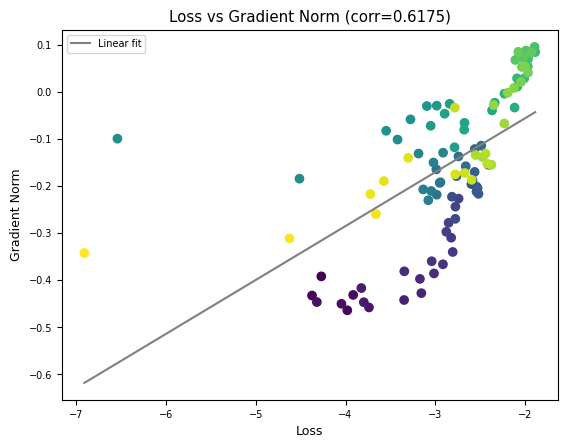

In [44]:
l_t = loss.mean(axis=0) - loss.mean(0).min()
x = jnp.log(l_t+1e-3)
y = jnp.log(grad_norm+1e-3)

ts = jnp.linspace(0, env.s_model.t_max, loss.shape[1])
plt.scatter(x, y, c=ts, cmap="viridis")
plt.xlabel("Loss")
plt.ylabel("Gradient Norm")

# linear correlationbetween loss and grad norm
corr = jnp.corrcoef(x, y)[0, 1]
print("Correlation between loss and gradient norm:", corr)

# linear fit
from scipy.stats import linregress
slope, intercept, r_value, p_value, std_err = linregress(x, y)
print(f"Linear fit: grad_norm = {slope:.4f} * loss + {intercept:.4f} (R^2={r_value**2:.4f})")

# plot with linear fit
x_loss = jnp.linspace(x.min(), x.max(), 100)
plt.plot(x_loss, slope * x_loss + intercept, color="gray", label="Linear fit")
plt.legend()
plt.title(f"Loss vs Gradient Norm (corr={corr:.4f})")

### plotting

In [71]:
grads.shape

(100, 3768320)

In [89]:
loss.mean(axis=0).shape, grads.shape

((100,), (100, 3768320))

In [98]:
loss.mean(axis=0).min()

0.57586133

Linear fit: grad_norm = 0.0637 * loss + -0.1374 (R^2=0.4413)


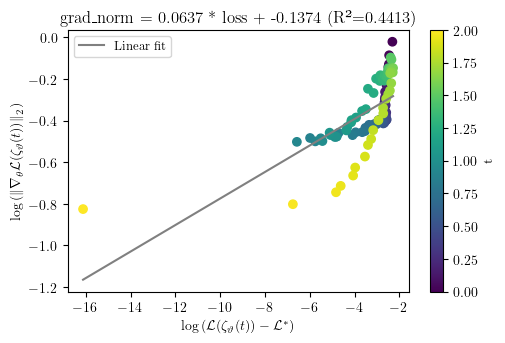

In [104]:
run_id = "4pshyv56"
run_id = "nultmcbl"
data = np.load(f"loss_and_grads_{run_id}.npz")

loss, grads = data['loss'], data['grads']
x = jnp.log(loss.mean(axis=0) - loss.mean(axis=0).min() + 1e-7)
y = jnp.log(jnp.linalg.norm(grads, axis=-1) + 1e-7)

ts = jnp.linspace(0, env.s_model.t_max, loss.shape[1])
plt.figure(figsize=figsize)
plt.scatter(x, y, c=ts, cmap="viridis")
plt.xlabel(r"$\log \left( \mathcal{L}(\zeta_\vartheta(t))-\mathcal{L}^\ast \right)$")
plt.ylabel(r"$\log \left( \|\nabla_\theta\mathcal{L}(\zeta_\vartheta(t))\|_2 \right)$")
colorbar = plt.colorbar()
colorbar.set_label("t")

# linear fit
from scipy.stats import linregress
slope, intercept, r_value, p_value, std_err = linregress(x, y)
print(f"Linear fit: grad_norm = {slope:.4f} * loss + {intercept:.4f} (R^2={r_value**2:.4f})")

# plot with linear fit
x_loss = jnp.linspace(x.min(), x.max(), 100)
plt.plot(x_loss, slope * x_loss + intercept, color="gray", label="Linear fit")
plt.legend()
plt.title(f"grad_norm = {slope:.4f} * loss + {intercept:.4f} (R²={r_value**2:.4f})")

plt.savefig(f"loss_vs_gradnorm_{run_id}.pdf", bbox_inches="tight")


In [5]:
run_id = "4pshyv56"
# run_id = "nultmcbl"
file_name = f"loss_and_grads_r7trynb3_ALC3_1_ARC-Challenge.npz"
# file_name = f"loss_and_grads_illmc5dx_ALC3_1_wino_s.npz"

data = np.load(file_name)
loss, grads = data['loss'], data['grads']
np.savez(f"{file_name}_compressed.npz", loss=loss.mean(axis=0), grads=jnp.linalg.norm(grads, axis=-1))